# K-Nearest Neighbors (Week 8)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             mean_squared_error, mean_absolute_error, r2_score)
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. LOAD AND AUDIT DATA
# ==========================================
path_a = '/content/Dataset A - Customer Analysis.csv'
path_b = '/content/Dataset B - Marketing & Product Analysis.csv'

df_a_raw = pd.read_csv(path_a, sep='\t')
df_b_raw = pd.read_csv(path_b)

print("=== Dataset A Audit ===")
print(df_a_raw.info())
print(f"Dataset A Raw Shape: {df_a_raw.shape}")
print("Missing values in A:\n", df_a_raw.isnull().sum()[df_a_raw.isnull().sum() > 0])

print("\n=== Dataset B Audit ===")
print(df_b_raw.info())
print(f"Dataset B Raw Shape: {df_b_raw.shape}")
print("Missing values in B:\n", df_b_raw.isnull().sum()[df_b_raw.isnull().sum() > 0])

=== Dataset A Audit ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurcha

In [ ]:
# ==========================================
# 2. FEATURE ENGINEERING & LEAKAGE CONTROL
# ==========================================

# --- Dataset A Feature Engineering ---
df_a = df_a_raw.copy()
df_a['Dt_Customer'] = pd.to_datetime(df_a['Dt_Customer'], errors='coerce')

# Reference Date for tenure (based on maximum registration date + buffer)
ref_date = pd.to_datetime('2015-01-01')

df_a['Age'] = 2015 - df_a['Year_Birth']
# Impute missing tenure dates prior to calculating tenure
tenure_median = (ref_date - df_a['Dt_Customer']).dt.days.median()
df_a['Tenure'] = (ref_date - df_a['Dt_Customer']).dt.days.fillna(tenure_median)
df_a['Children'] = df_a['Kidhome'] + df_a['Teenhome']

purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_a['TotalPurchases'] = df_a[purchase_cols].sum(axis=1)

cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df_a['AcceptedAny'] = (df_a[cmp_cols].sum(axis=1) > 0).astype(int)

# Target definitions
spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df_a['TotalSpend'] = df_a[spend_cols].sum(axis=1)

# Predictor isolation
leakage_cols_a = spend_cols + ['ID', 'Dt_Customer', 'Year_Birth', 'Kidhome', 'Teenhome', 'Z_CostContact', 'Z_Revenue']

X_a_cls = df_a.drop(columns=leakage_cols_a + ['Response', 'TotalSpend'], errors='ignore')
y_a_cls = df_a['Response']

X_a_reg = df_a.drop(columns=leakage_cols_a + ['Response', 'TotalSpend'], errors='ignore')
y_a_reg = df_a['TotalSpend']

# --- Dataset B Feature Engineering ---
df_b = df_b_raw.copy()
df_b['ConversionRate'] = np.where(df_b['Clicks'] > 0, df_b['Conversions'] / df_b['Clicks'], 0)
df_b['RevenuePerClick'] = np.where(df_b['Clicks'] > 0, df_b['Revenue_Generated'] / df_b['Clicks'], 0)
df_b['ProfitProxy'] = df_b['Revenue_Generated'] - df_b['Budget']

roi_median = df_b['ROI'].median()
df_b['HighROI'] = (df_b['ROI'] > roi_median).astype(int)

id_cols_b = ['Campaign_ID', 'Product_ID', 'Customer_ID', 'Flash_Sale_ID', 'Bundle_ID']

# Prevent Leakage for Dataset B Tasks
X_b_cls = df_b.drop(columns=id_cols_b + ['ROI', 'Revenue_Generated', 'ProfitProxy', 'RevenuePerClick', 'HighROI'], errors='ignore')
y_b_cls = df_b['HighROI']

X_b_reg = df_b.drop(columns=id_cols_b + ['ROI', 'ProfitProxy', 'RevenuePerClick', 'HighROI', 'Revenue_Generated'], errors='ignore')
y_b_reg = df_b['Revenue_Generated']

print("Dataset A Target Response Class Balance:")
print(y_a_cls.value_counts(normalize=True))
print("\nDataset B Target HighROI Class Balance:")
print(y_b_cls.value_counts(normalize=True))

Dataset A Target Response Class Balance:
Response
0    0.850893
1    0.149107
Name: proportion, dtype: float64

Dataset B Target HighROI Class Balance:
HighROI
0    0.5002
1    0.4998
Name: proportion, dtype: float64


In [ ]:
# ==========================================
# 3. PREPROCESSING PIPELINES & DATA SPLITS
# ==========================================

def create_preprocessor(X, scale=True):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

    num_steps = [('imputer', SimpleImputer(strategy='median'))]
    if scale:
        num_steps.append(('scaler', StandardScaler()))

    num_transformer = Pipeline(steps=num_steps)
    cat_transformer = Pipeline(steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    ])

    return ColumnTransformer(transformers=[
        ('num', num_transformer, num_cols),
        ('cat', cat_transformer, cat_cols)
    ])

# Split & Preprocess Customer Classification
X_train_a_cls, X_test_a_cls, y_train_a_cls, y_test_a_cls = train_test_split(
    X_a_cls, y_a_cls, test_size=0.2, random_state=42, stratify=y_a_cls
)
prep_a_cls_scaled = create_preprocessor(X_train_a_cls, scale=True)
X_tr_a_cls_s = prep_a_cls_scaled.fit_transform(X_train_a_cls)
X_te_a_cls_s = prep_a_cls_scaled.transform(X_test_a_cls)

prep_a_cls_unscaled = create_preprocessor(X_train_a_cls, scale=False)
X_tr_a_cls_u = prep_a_cls_unscaled.fit_transform(X_train_a_cls)
X_te_a_cls_u = prep_a_cls_unscaled.transform(X_test_a_cls)

# Split & Preprocess Customer Regression
X_train_a_reg, X_test_a_reg, y_train_a_reg, y_test_a_reg = train_test_split(
    X_a_reg, y_a_reg, test_size=0.2, random_state=42
)
prep_a_reg_scaled = create_preprocessor(X_train_a_reg, scale=True)
X_tr_a_reg_s = prep_a_reg_scaled.fit_transform(X_train_a_reg)
X_te_a_reg_s = prep_a_reg_scaled.transform(X_test_a_reg)

# Split & Preprocess Campaign Classification
X_train_b_cls, X_test_b_cls, y_train_b_cls, y_test_b_cls = train_test_split(
    X_b_cls, y_b_cls, test_size=0.2, random_state=42, stratify=y_b_cls
)
prep_b_cls_scaled = create_preprocessor(X_train_b_cls, scale=True)
X_tr_b_cls_s = prep_b_cls_scaled.fit_transform(X_train_b_cls)
X_te_b_cls_s = prep_b_cls_scaled.transform(X_test_b_cls)

# Split & Preprocess Campaign Regression
X_train_b_reg, X_test_b_reg, y_train_b_reg, y_test_b_reg = train_test_split(
    X_b_reg, y_b_reg, test_size=0.2, random_state=42
)
prep_b_reg_scaled = create_preprocessor(X_train_b_reg, scale=True)
X_tr_b_reg_s = prep_b_reg_scaled.fit_transform(X_train_b_reg)
X_te_b_reg_s = prep_b_reg_scaled.transform(X_test_b_reg)

print("Data Splitting and Preprocessing complete.")

Data Splitting and Preprocessing complete.


In [ ]:
# ==========================================
# 4. KNN MODEL EVALUATION PIPELINES
# ==========================================

def evaluate_knn_classifier(X_train, y_train, X_test, y_test):
    metrics_to_test = {
        'Euclidean': {'metric': 'minkowski', 'p': 2},
        'Manhattan': {'metric': 'minkowski', 'p': 1},
        'Minkowski_p3': {'metric': 'minkowski', 'p': 3},
        'Chebyshev': {'metric': 'chebyshev'},
        'Cosine': {'metric': 'cosine'}
    }

    results = {}
    k_range = [3, 5, 7, 11, 15, 21, 29]

    for label, param in metrics_to_test.items():
        grid = GridSearchCV(
            KNeighborsClassifier(),
            param_grid={'n_neighbors': k_range},
            cv=5,
            scoring='roc_auc'
        )
        grid.fit(X_train, y_train)
        best_knn = grid.best_estimator_
        preds = best_knn.predict(X_test)
        probs = best_knn.predict_proba(X_test)[:, 1]

        results[label] = {
            'Best k': grid.best_params_['n_neighbors'],
            'Accuracy': accuracy_score(y_test, preds),
            'Precision': precision_score(y_test, preds, zero_division=0),
            'Recall': recall_score(y_test, preds, zero_division=0),
            'F1': f1_score(y_test, preds, zero_division=0),
            'ROC-AUC': roc_auc_score(y_test, probs),
            'model': best_knn,
            'probs': probs
        }
    return results

def evaluate_knn_regressor(X_train, y_train, X_test, y_test):
    metrics_to_test = {
        'Euclidean': {'metric': 'minkowski', 'p': 2},
        'Manhattan': {'metric': 'minkowski', 'p': 1},
        'Minkowski_p3': {'metric': 'minkowski', 'p': 3},
        'Chebyshev': {'metric': 'chebyshev'},
        'Cosine': {'metric': 'cosine'}
    }

    results = {}
    k_range = [3, 5, 7, 11, 15, 21, 29]

    for label, param in metrics_to_test.items():
        grid = GridSearchCV(
            KNeighborsRegressor(),
            param_grid={'n_neighbors': k_range},
            cv=5,
            scoring='r2'
        )
        grid.fit(X_train, y_train)
        best_knn = grid.best_estimator_
        preds = best_knn.predict(X_test)

        results[label] = {
            'Best k': grid.best_params_['n_neighbors'],
            'RMSE': np.sqrt(mean_squared_error(y_test, preds)),
            'MAE': mean_absolute_error(y_test, preds),
            'R2': r2_score(y_test, preds),
            'model': best_knn,
            'preds': preds
        }
    return results

In [ ]:
# Execute modeling tasks
print("=== Model Tuning & Testing: Dataset A Classification (Response) ===")
results_a_cls = evaluate_knn_classifier(X_tr_a_cls_s, y_train_a_cls, X_te_a_cls_s, y_test_a_cls)
display(pd.DataFrame(results_a_cls).T[['Best k', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']])

print("\n=== Model Tuning & Testing: Dataset A Regression (TotalSpend) ===")
results_a_reg = evaluate_knn_regressor(X_tr_a_reg_s, y_train_a_reg, X_te_a_reg_s, y_test_a_reg)
display(pd.DataFrame(results_a_reg).T[['Best k', 'RMSE', 'MAE', 'R2']])

print("\n=== Model Tuning & Testing: Dataset B Classification (HighROI) ===")
# Sub-sample training split to accelerate CV runs safely on Dataset B (10k records)
results_b_cls = evaluate_knn_classifier(X_tr_b_cls_s[:3000], y_train_b_cls[:3000], X_te_b_cls_s, y_test_b_cls)
display(pd.DataFrame(results_b_cls).T[['Best k', 'Accuracy', 'Precision', 'Recall', 'F1', 'ROC-AUC']])

print("\n=== Model Tuning & Testing: Dataset B Regression (Revenue_Generated) ===")
results_b_reg = evaluate_knn_regressor(X_tr_b_reg_s[:3000], y_train_b_reg[:3000].values, X_te_b_reg_s, y_test_b_reg)
display(pd.DataFrame(results_b_reg).T[['Best k', 'RMSE', 'MAE', 'R2']])

=== Model Tuning & Testing: Dataset A Classification (Response) ===


,Best k,Accuracy,Precision,Recall,F1,ROC-AUC
Euclidean,21,0.868304,0.633333,0.283582,0.391753,0.841051
Manhattan,21,0.868304,0.633333,0.283582,0.391753,0.841051
Minkowski_p3,21,0.868304,0.633333,0.283582,0.391753,0.841051
Chebyshev,21,0.868304,0.633333,0.283582,0.391753,0.841051
Cosine,21,0.868304,0.633333,0.283582,0.391753,0.841051



=== Model Tuning & Testing: Dataset A Regression (TotalSpend) ===


,Best k,RMSE,MAE,R2
Euclidean,7,279.904618,163.396046,0.779656
Manhattan,7,279.904618,163.396046,0.779656
Minkowski_p3,7,279.904618,163.396046,0.779656
Chebyshev,7,279.904618,163.396046,0.779656
Cosine,7,279.904618,163.396046,0.779656



=== Model Tuning & Testing: Dataset B Classification (HighROI) ===


,Best k,Accuracy,Precision,Recall,F1,ROC-AUC
Euclidean,3,0.4945,0.494676,0.511,0.502705,0.489323
Manhattan,3,0.4945,0.494676,0.511,0.502705,0.489323
Minkowski_p3,3,0.4945,0.494676,0.511,0.502705,0.489323
Chebyshev,3,0.4945,0.494676,0.511,0.502705,0.489323
Cosine,3,0.4945,0.494676,0.511,0.502705,0.489323



=== Model Tuning & Testing: Dataset B Regression (Revenue_Generated) ===


,Best k,RMSE,MAE,R2
Euclidean,29,29116.229083,25096.039104,-0.039643
Manhattan,29,29116.229083,25096.039104,-0.039643
Minkowski_p3,29,29116.229083,25096.039104,-0.039643
Chebyshev,29,29116.229083,25096.039104,-0.039643
Cosine,29,29116.229083,25096.039104,-0.039643


In [ ]:
# ==========================================
# 5. FEATURE SCALING DEMONSTRATION
# ==========================================
print("=== Feature Scaling Performance Audit (Dataset A, Euclidean KNN Classification) ===")
knn_scaled = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2).fit(X_tr_a_cls_s, y_train_a_cls)
knn_unscaled = KNeighborsClassifier(n_neighbors=5, metric='minkowski', p=2).fit(X_tr_a_cls_u, y_train_a_cls)

scaled_preds = knn_scaled.predict(X_te_a_cls_s)
unscaled_preds = knn_unscaled.predict(X_te_a_cls_u)

scaling_demo = pd.DataFrame({
    'Configuration': ['Scaled Inputs', 'Unscaled Inputs'],
    'Accuracy': [accuracy_score(y_test_a_cls, scaled_preds), accuracy_score(y_test_a_cls, unscaled_preds)],
    'F1-Score': [f1_score(y_test_a_cls, scaled_preds, zero_division=0), f1_score(y_test_a_cls, unscaled_preds, zero_division=0)],
    'ROC-AUC': [roc_auc_score(y_test_a_cls, knn_scaled.predict_proba(X_te_a_cls_s)[:,1]),
                roc_auc_score(y_test_a_cls, knn_unscaled.predict_proba(X_te_a_cls_u)[:,1])]
})
display(scaling_demo)

=== Feature Scaling Performance Audit (Dataset A, Euclidean KNN Classification) ===


,Configuration,Accuracy,F1-Score,ROC-AUC
0,Scaled Inputs,0.868304,0.427184,0.818584
1,Unscaled Inputs,0.819196,0.147368,0.692698


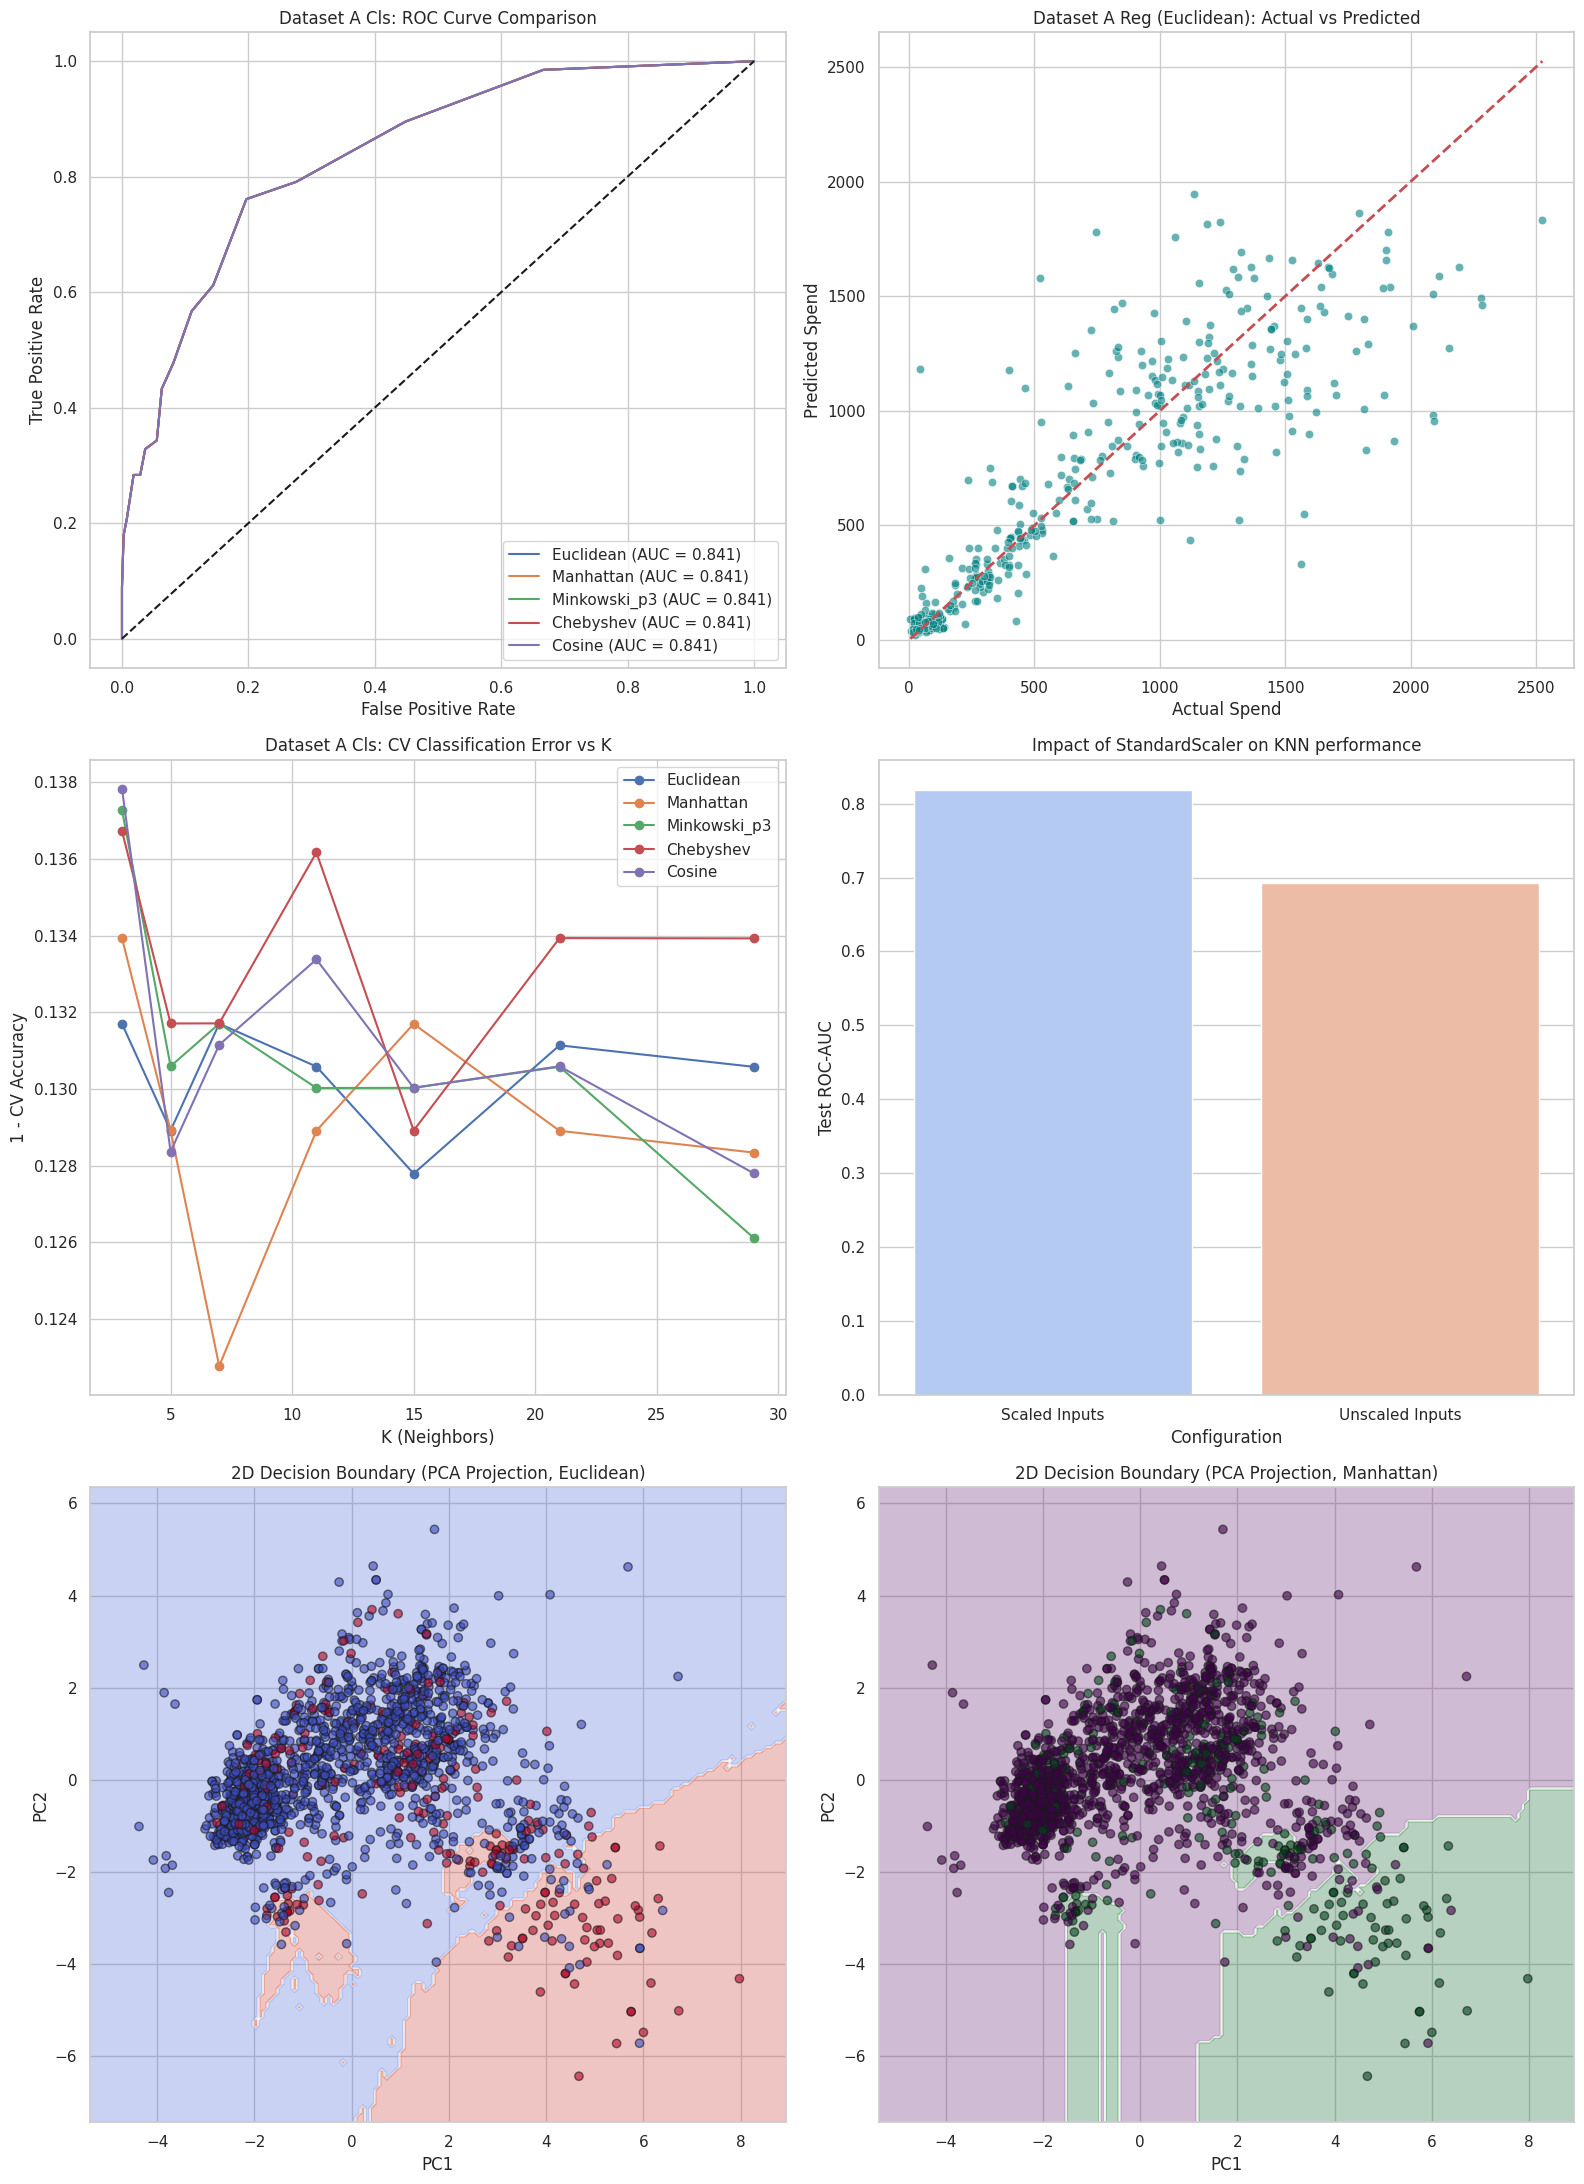

In [ ]:
# ==========================================
# 6. DIAGNOSTIC PLOTS & VISUALIZATIONS
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(3, 2, figsize=(16, 22))

# Plot A: ROC Curves (Dataset A)
for label, metrics in results_a_cls.items():
    fpr, tpr, _ = roc_curve(y_test_a_cls, metrics['probs'])
    axes[0, 0].plot(fpr, tpr, label=f"{label} (AUC = {metrics['ROC-AUC']:.3f})")
axes[0, 0].plot([0, 1], [0, 1], 'k--')
axes[0, 0].set_title("Dataset A Cls: ROC Curve Comparison")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()

# Plot B: Actual vs Predicted Spend (Dataset A Reg Champion)
best_reg_key_a = max(results_a_reg, key=lambda k: results_a_reg[k]['R2'])
preds_a_reg = results_a_reg[best_reg_key_a]['preds']
sns.scatterplot(x=y_test_a_reg, y=preds_a_reg, color='teal', alpha=0.6, ax=axes[0, 1])
axes[0, 1].plot([y_test_a_reg.min(), y_test_a_reg.max()], [y_test_a_reg.min(), y_test_a_reg.max()], 'r--', lw=2)
axes[0, 1].set_title(f"Dataset A Reg ({best_reg_key_a}): Actual vs Predicted")
axes[0, 1].set_xlabel("Actual Spend")
axes[0, 1].set_ylabel("Predicted Spend")

# Plot C: Cross-validated Error curves for metric selection (Dataset A)
for metric_label in results_a_cls.keys():
    cv_scores = []
    ks = [3, 5, 7, 11, 15, 21, 29]
    for k in ks:
        if metric_label == 'Chebyshev':
            model = KNeighborsClassifier(n_neighbors=k, metric='chebyshev')
        elif metric_label == 'Cosine':
            model = KNeighborsClassifier(n_neighbors=k, metric='cosine')
        else:
            p_val = 1 if metric_label == 'Manhattan' else (3 if metric_label == 'Minkowski_p3' else 2)
            model = KNeighborsClassifier(n_neighbors=k, metric='minkowski', p=p_val)
        cv_scores.append(1 - np.mean(cross_val_score(model, X_tr_a_cls_s, y_train_a_cls, cv=5, scoring='accuracy')))
    axes[1, 0].plot(ks, cv_scores, marker='o', label=metric_label)
axes[1, 0].set_title("Dataset A Cls: CV Classification Error vs K")
axes[1, 0].set_xlabel("K (Neighbors)")
axes[1, 0].set_ylabel("1 - CV Accuracy")
axes[1, 0].legend()

# Plot D: Scaling Comparison Bar Chart
sns.barplot(x='Configuration', y='ROC-AUC', data=scaling_demo, palette='coolwarm', ax=axes[1, 1])
axes[1, 1].set_title("Impact of StandardScaler on KNN performance")
axes[1, 1].set_ylabel("Test ROC-AUC")

# Plot E: 2D PCA Decision Boundary Projection (Euclidean)
pca = PCA(n_components=2)
X_tr_pca = pca.fit_transform(X_tr_a_cls_s)
knn_2d = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=2).fit(X_tr_pca, y_train_a_cls)

x_min, x_max = X_tr_pca[:, 0].min() - 1, X_tr_pca[:, 0].max() + 1
y_min, y_max = X_tr_pca[:, 1].min() - 1, X_tr_pca[:, 1].max() + 1
xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.1), np.arange(y_min, y_max, 0.1))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes[2, 0].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
axes[2, 0].scatter(X_tr_pca[:, 0], X_tr_pca[:, 1], c=y_train_a_cls, cmap='coolwarm', edgecolors='k', alpha=0.6)
axes[2, 0].set_title("2D Decision Boundary (PCA Projection, Euclidean)")
axes[2, 0].set_xlabel("PC1")
axes[2, 0].set_ylabel("PC2")

# Plot F: 2D PCA Decision Boundary Projection (Manhattan)
knn_2d_man = KNeighborsClassifier(n_neighbors=15, metric='minkowski', p=1).fit(X_tr_pca, y_train_a_cls)
Z_man = knn_2d_man.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

axes[2, 1].contourf(xx, yy, Z_man, alpha=0.3, cmap='PRGn')
axes[2, 1].scatter(X_tr_pca[:, 0], X_tr_pca[:, 1], c=y_train_a_cls, cmap='PRGn', edgecolors='k', alpha=0.6)
axes[2, 1].set_title("2D Decision Boundary (PCA Projection, Manhattan)")
axes[2, 1].set_xlabel("PC1")
axes[2, 1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

# Gradient Boost (Week 9)

In [ ]:
%%bash
pip install -q xgboost lightgbm shap optuna

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import warnings
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    precision_recall_curve, auc, confusion_matrix, mean_squared_error, mean_absolute_error, r2_score
)
import xgboost as xgb
import lightgbm as lgb
import shap

warnings.filterwarnings('ignore')
np.random.seed(42)
sns.set_theme(style="whitegrid")

# ==========================================
# 1. LOAD AND PREPARE DATASETS
# ==========================================
path_a = '/content/Dataset A - Customer Analysis.csv'
path_b = '/content/Dataset B - Marketing & Product Analysis.csv'

df_a = pd.read_csv(path_a, sep='\t')
df_b = pd.read_csv(path_b)

# --- Feature Engineering: Dataset A ---
df_a['Dt_Customer'] = pd.to_datetime(df_a['Dt_Customer'], errors='coerce')
income_median = df_a['Income'].median()
df_a['Income'] = df_a['Income'].fillna(income_median)

ref_date = pd.to_datetime('2015-01-01')
df_a['Age'] = 2015 - df_a['Year_Birth']
tenure_median = (ref_date - df_a['Dt_Customer']).dt.days.median()
df_a['Tenure'] = (ref_date - df_a['Dt_Customer']).dt.days.fillna(tenure_median)
df_a['Children'] = df_a['Kidhome'] + df_a['Teenhome']

purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_a['TotalPurchases'] = df_a[purchase_cols].sum(axis=1)

cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
df_a['AcceptedAny'] = (df_a[cmp_cols].sum(axis=1) > 0).astype(int)

spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df_a['TotalSpend'] = df_a[spend_cols].sum(axis=1)
median_spend = df_a['TotalSpend'].median()
df_a['HighValue'] = (df_a['TotalSpend'] > median_spend).astype(int)

# Predictor isolation
leakage_a = spend_cols + ['ID', 'Dt_Customer', 'Year_Birth', 'Kidhome', 'Teenhome', 'Z_CostContact', 'Z_Revenue']
X_a = df_a.drop(columns=leakage_a + ['Response', 'TotalSpend', 'HighValue'], errors='ignore')
y_a_resp = df_a['Response']
y_a_hval = df_a['HighValue']
y_a_spend = df_a['TotalSpend']

# --- Feature Engineering: Dataset B ---
df_b['ConversionRate'] = np.where(df_b['Clicks'] > 0, df_b['Conversions'] / df_b['Clicks'], 0)
df_b['RevenuePerClick'] = np.where(df_b['Clicks'] > 0, df_b['Revenue_Generated'] / df_b['Clicks'], 0)
df_b['ProfitProxy'] = df_b['Revenue_Generated'] - df_b['Budget']

roi_median = df_b['ROI'].median()
df_b['HighROI'] = (df_b['ROI'] > roi_median).astype(int)
conv_median = df_b['ConversionRate'].median()
df_b['HighConversion'] = (df_b['ConversionRate'] > conv_median).astype(int)

# Predictor isolation
id_cols_b = ['Campaign_ID', 'Product_ID', 'Customer_ID', 'Flash_Sale_ID', 'Bundle_ID']
leakage_b = id_cols_b + ['ProfitProxy', 'RevenuePerClick']

X_b_cls = df_b.drop(columns=leakage_b + ['HighROI', 'HighConversion', 'Revenue_Generated', 'ROI'], errors='ignore')
y_b_roi = df_b['HighROI']
y_b_conv = df_b['HighConversion']

# Regression feature sets
X_b_reg_rev = df_b.drop(columns=leakage_b + ['HighROI', 'HighConversion', 'Revenue_Generated', 'ROI'], errors='ignore')
y_b_rev = df_b['Revenue_Generated']

X_b_reg_roi = df_b.drop(columns=leakage_b + ['HighROI', 'HighConversion', 'Revenue_Generated', 'ROI'], errors='ignore')
y_b_roi_cont = df_b['ROI']

print("Dataset A prepped features shape:", X_a.shape)
print("Dataset B prepped features shape:", X_b_cls.shape)

Dataset A prepped features shape: (2240, 20)
Dataset B prepped features shape: (10000, 11)


In [ ]:
# ==========================================
# 2. UNIVERSAL PREPROCESSING PIPELINES
# ==========================================
def build_preprocessor(X):
    num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
    cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()
    num_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='median'))])
    cat_transformer = Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')), ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])
    return ColumnTransformer(transformers=[('num', num_transformer, num_cols), ('cat', cat_transformer, cat_cols)]), num_cols, cat_cols

prep_a, num_a, cat_a = build_preprocessor(X_a)
prep_b, num_b, cat_b = build_preprocessor(X_b_cls)

# Generate feature names
prep_a.fit(X_a)
encoded_cat_a = prep_a.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_a).tolist() if cat_a else []
feature_names_a = num_a + encoded_cat_a

prep_b.fit(X_b_cls)
encoded_cat_b = prep_b.named_transformers_['cat'].named_steps['onehot'].get_feature_names_out(cat_b).tolist() if cat_b else []
feature_names_b = num_b + encoded_cat_b

In [ ]:
# ==========================================
# 3. HELPER EVALUATION FUNCTIONS
# ==========================================
def eval_classification(name, model, X_train, y_train, X_test, y_test):
    t0 = time.time()
    model.fit(X_train, y_train)
    t_train = time.time() - t0
    preds = model.predict(X_test)
    probs = model.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, zero_division=0)
    rec = recall_score(y_test, preds, zero_division=0)
    f1 = f1_score(y_test, preds, zero_division=0)
    roc_auc = roc_auc_score(y_test, probs)
    p, r, _ = precision_recall_curve(y_test, probs)
    pr_auc = auc(r, p)

    return {
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc,
        'PR-AUC': pr_auc,
        'Train Time': t_train,
        'preds': preds,
        'probs': probs
    }

def eval_regression(name, model, X_train, y_train, X_test, y_test):
    t0 = time.time()
    model.fit(X_train, y_train)
    t_train = time.time() - t0
    preds = model.predict(X_test)

    rmse = np.sqrt(mean_squared_error(y_test, preds))
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)

    return {
        'Model': name,
        'RMSE': rmse,
        'MAE': mae,
        'R2': r2,
        'Train Time': t_train,
        'preds': preds
    }

In [ ]:
# =========================================================================
# 4. DATASET A CLASSIFICATION TASK (TARGET: Response)
# =========================================================================
print("=== TRAINING DATASET A CLASSIFICATION (Response) ===")
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_a, y_a_resp, test_size=0.2, random_state=42, stratify=y_a_resp
)
X_train_a_p = prep_a.transform(X_train_a)
X_test_a_p = prep_a.transform(X_test_a)

# Define hyperparameter search spaces
gb_space = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 8],
    'subsample': [0.7, 1.0]
}

xgb_space = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 8],
    'subsample': [0.7, 1.0],
    'colsample_bytree': [0.7, 1.0]
}

lgb_space = {
    'n_estimators': [50, 100, 150],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 8],
    'subsample': [0.7, 1.0],
    'colsample_bytree': [0.7, 1.0],
    'verbosity': [-1]
}

# Hyperparameter tuning via CV for each paradigm
gb_search_a = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), gb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_a_p, y_train_a)
xgb_search_a = RandomizedSearchCV(xgb.XGBClassifier(random_state=42, eval_metric='logloss'), xgb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_a_p, y_train_a)
lgb_search_a = RandomizedSearchCV(lgb.LGBMClassifier(random_state=42), lgb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_a_p, y_train_a)

# Evaluate Champion Implementations against baselines
results_a_cls = []
results_a_cls.append(eval_classification('Scikit-Learn GB', gb_search_a.best_estimator_, X_train_a_p, y_train_a, X_test_a_p, y_test_a))
results_a_cls.append(eval_classification('XGBoost', xgb_search_a.best_estimator_, X_train_a_p, y_train_a, X_test_a_p, y_test_a))
results_a_cls.append(eval_classification('LightGBM', lgb_search_a.best_estimator_, X_train_a_p, y_train_a, X_test_a_p, y_test_a))
results_a_cls.append(eval_classification('Random Forest', RandomForestClassifier(random_state=42), X_train_a_p, y_train_a, X_test_a_p, y_test_a))
results_a_cls.append(eval_classification('Logistic Regression', LogisticRegression(random_state=42), X_train_a_p, y_train_a, X_test_a_p, y_test_a))

df_a_cls_results = pd.DataFrame(results_a_cls)
display(df_a_cls_results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Train Time']])

=== TRAINING DATASET A CLASSIFICATION (Response) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Train Time
0,Scikit-Learn GB,0.901786,0.794872,0.462687,0.584906,0.910115,0.715141,0.490241
1,XGBoost,0.897321,0.783784,0.432836,0.557692,0.898245,0.682010,0.075200
2,LightGBM,0.883929,0.702703,0.388060,0.500000,0.894915,0.679732,0.056270
3,Random Forest,0.895089,0.833333,0.373134,0.515464,0.884299,0.675276,0.238934
4,Logistic Regression,0.850446,0.500000,0.104478,0.172840,0.766659,0.378265,0.018466


In [ ]:
# =========================================================================
# 5. DATASET A REGRESSION TASK (TARGET: TotalSpend)
# =========================================================================
print("=== TRAINING DATASET A REGRESSION (TotalSpend) ===")
X_train_a_r, X_test_a_r, y_train_a_r, y_test_a_r = train_test_split(
    X_a, y_a_spend, test_size=0.2, random_state=42
)
X_train_a_rp = prep_a.transform(X_train_a_r)
X_test_a_rp = prep_a.transform(X_test_a_r)

# Hyperparameter tuning
gb_search_a_reg = RandomizedSearchCV(GradientBoostingRegressor(random_state=42), gb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_a_rp, y_train_a_r)
xgb_search_a_reg = RandomizedSearchCV(xgb.XGBRegressor(random_state=42), xgb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_a_rp, y_train_a_r)
lgb_search_a_reg = RandomizedSearchCV(lgb.LGBMRegressor(random_state=42, verbosity=-1), lgb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_a_rp, y_train_a_r)

results_a_reg = []
results_a_reg.append(eval_regression('Scikit-Learn GB', gb_search_a_reg.best_estimator_, X_train_a_rp, y_train_a_r, X_test_a_rp, y_test_a_r))
results_a_reg.append(eval_regression('XGBoost', xgb_search_a_reg.best_estimator_, X_train_a_rp, y_train_a_r, X_test_a_rp, y_test_a_r))
results_a_reg.append(eval_regression('LightGBM', lgb_search_a_reg.best_estimator_, X_train_a_rp, y_train_a_r, X_test_a_rp, y_test_a_r))
results_a_reg.append(eval_regression('Random Forest', RandomForestRegressor(random_state=42), X_train_a_rp, y_train_a_r, X_test_a_rp, y_test_a_r))
results_a_reg.append(eval_regression('Linear Regression', LinearRegression(), X_train_a_rp, y_train_a_r, X_test_a_rp, y_test_a_r))

df_a_reg_results = pd.DataFrame(results_a_reg)
display(df_a_reg_results[['Model', 'RMSE', 'MAE', 'R2', 'Train Time']])

=== TRAINING DATASET A REGRESSION (TotalSpend) ===


,Model,RMSE,MAE,R2,Train Time
0,Scikit-Learn GB,195.936814,110.597756,0.892027,0.391752
1,XGBoost,205.580039,113.197617,0.881138,0.078137
2,LightGBM,213.807940,118.784075,0.871433,0.061286
3,Random Forest,205.161836,110.937879,0.881621,0.943448
4,Linear Regression,295.705742,193.705749,0.754076,0.001825


In [ ]:
# =========================================================================
# 6. DATASET B CLASSIFICATION TASK (TARGET: HighROI)
# =========================================================================
print("=== TRAINING DATASET B CLASSIFICATION (HighROI) ===")
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_b_cls, y_b_roi, test_size=0.2, random_state=42, stratify=y_b_roi
)
X_train_b_p = prep_b.transform(X_train_b)
X_test_b_p = prep_b.transform(X_test_b)

# Tuning using subset of Dataset B for execution speed optimization
gb_search_b = RandomizedSearchCV(GradientBoostingClassifier(random_state=42), gb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_b_p[:2000], y_train_b[:2000])
xgb_search_b = RandomizedSearchCV(xgb.XGBClassifier(random_state=42, eval_metric='logloss'), xgb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_b_p[:2000], y_train_b[:2000])
lgb_search_b = RandomizedSearchCV(lgb.LGBMClassifier(random_state=42, verbosity=-1), lgb_space, n_iter=5, cv=5, scoring='f1', random_state=42).fit(X_train_b_p[:2000], y_train_b[:2000])

results_b_cls = []
results_b_cls.append(eval_classification('Scikit-Learn GB', gb_search_b.best_estimator_, X_train_b_p, y_train_b, X_test_b_p, y_test_b))
results_b_cls.append(eval_classification('XGBoost', xgb_search_b.best_estimator_, X_train_b_p, y_train_b, X_test_b_p, y_test_b))
results_b_cls.append(eval_classification('LightGBM', lgb_search_b.best_estimator_, X_train_b_p, y_train_b, X_test_b_p, y_test_b))
results_b_cls.append(eval_classification('Random Forest', RandomForestClassifier(random_state=42), X_train_b_p, y_train_b, X_test_b_p, y_test_b))
results_b_cls.append(eval_classification('Logistic Regression', LogisticRegression(random_state=42), X_train_b_p, y_train_b, X_test_b_p, y_test_b))

df_b_cls_results = pd.DataFrame(results_b_cls)
display(df_b_cls_results[['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC', 'PR-AUC', 'Train Time']])

=== TRAINING DATASET B CLASSIFICATION (HighROI) ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,PR-AUC,Train Time
0,Scikit-Learn GB,0.4995,0.499526,0.527,0.512895,0.509618,0.508729,2.107305
1,XGBoost,0.5090,0.508588,0.533,0.520508,0.504949,0.504482,0.069501
2,LightGBM,0.5135,0.512821,0.540,0.526059,0.510542,0.509640,0.078540
3,Random Forest,0.5140,0.514706,0.490,0.502049,0.518168,0.517040,2.058862
4,Logistic Regression,0.4895,0.490846,0.563,0.524453,0.483275,0.480319,0.053885


In [ ]:
# =========================================================================
# 7. DATASET B REGRESSION TASK (TARGET: Revenue_Generated)
# =========================================================================
print("=== TRAINING DATASET B REGRESSION (Revenue_Generated) ===")
X_train_b_r, X_test_b_r, y_train_b_r, y_test_b_r = train_test_split(
    X_b_reg_rev, y_b_rev, test_size=0.2, random_state=42
)
X_train_b_rp = prep_b.transform(X_train_b_r)
X_test_b_rp = prep_b.transform(X_test_b_r)

# Hyperparameter tuning using subset for fast convergence
gb_search_b_reg = RandomizedSearchCV(GradientBoostingRegressor(random_state=42), gb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_b_rp[:2000], y_train_b_r[:2000])
xgb_search_b_reg = RandomizedSearchCV(xgb.XGBRegressor(random_state=42), xgb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_b_rp[:2000], y_train_b_r[:2000])
lgb_search_b_reg = RandomizedSearchCV(lgb.LGBMRegressor(random_state=42, verbosity=-1), lgb_space, n_iter=5, cv=5, scoring='r2', random_state=42).fit(X_train_b_rp[:2000], y_train_b_r[:2000])

results_b_reg = []
results_b_reg.append(eval_regression('Scikit-Learn GB', gb_search_b_reg.best_estimator_, X_train_b_rp, y_train_b_r, X_test_b_rp, y_test_b_r))
results_b_reg.append(eval_regression('XGBoost', xgb_search_b_reg.best_estimator_, X_train_b_rp, y_train_b_r, X_test_b_rp, y_test_b_r))
results_b_reg.append(eval_regression('LightGBM', lgb_search_b_reg.best_estimator_, X_train_b_rp, y_train_b_r, X_test_b_rp, y_test_b_r))
results_b_reg.append(eval_regression('Random Forest', RandomForestRegressor(random_state=42), X_train_b_rp, y_train_b_r, X_test_b_rp, y_test_b_r))
results_b_reg.append(eval_regression('Linear Regression', LinearRegression(), X_train_b_rp, y_train_b_r, X_test_b_rp, y_test_b_r))

df_b_reg_results = pd.DataFrame(results_b_reg)
display(df_b_reg_results[['Model', 'RMSE', 'MAE', 'R2', 'Train Time']])

=== TRAINING DATASET B REGRESSION (Revenue_Generated) ===


,Model,RMSE,MAE,R2,Train Time
0,Scikit-Learn GB,28585.132438,24719.983705,-0.002061,1.843434
1,XGBoost,28577.501115,24720.636588,-0.001526,0.194925
2,LightGBM,28569.902751,24719.358879,-0.000994,0.046250
3,Random Forest,29053.424877,24979.422972,-0.035162,7.795095
4,Linear Regression,28587.606792,24737.010382,-0.002235,0.003131


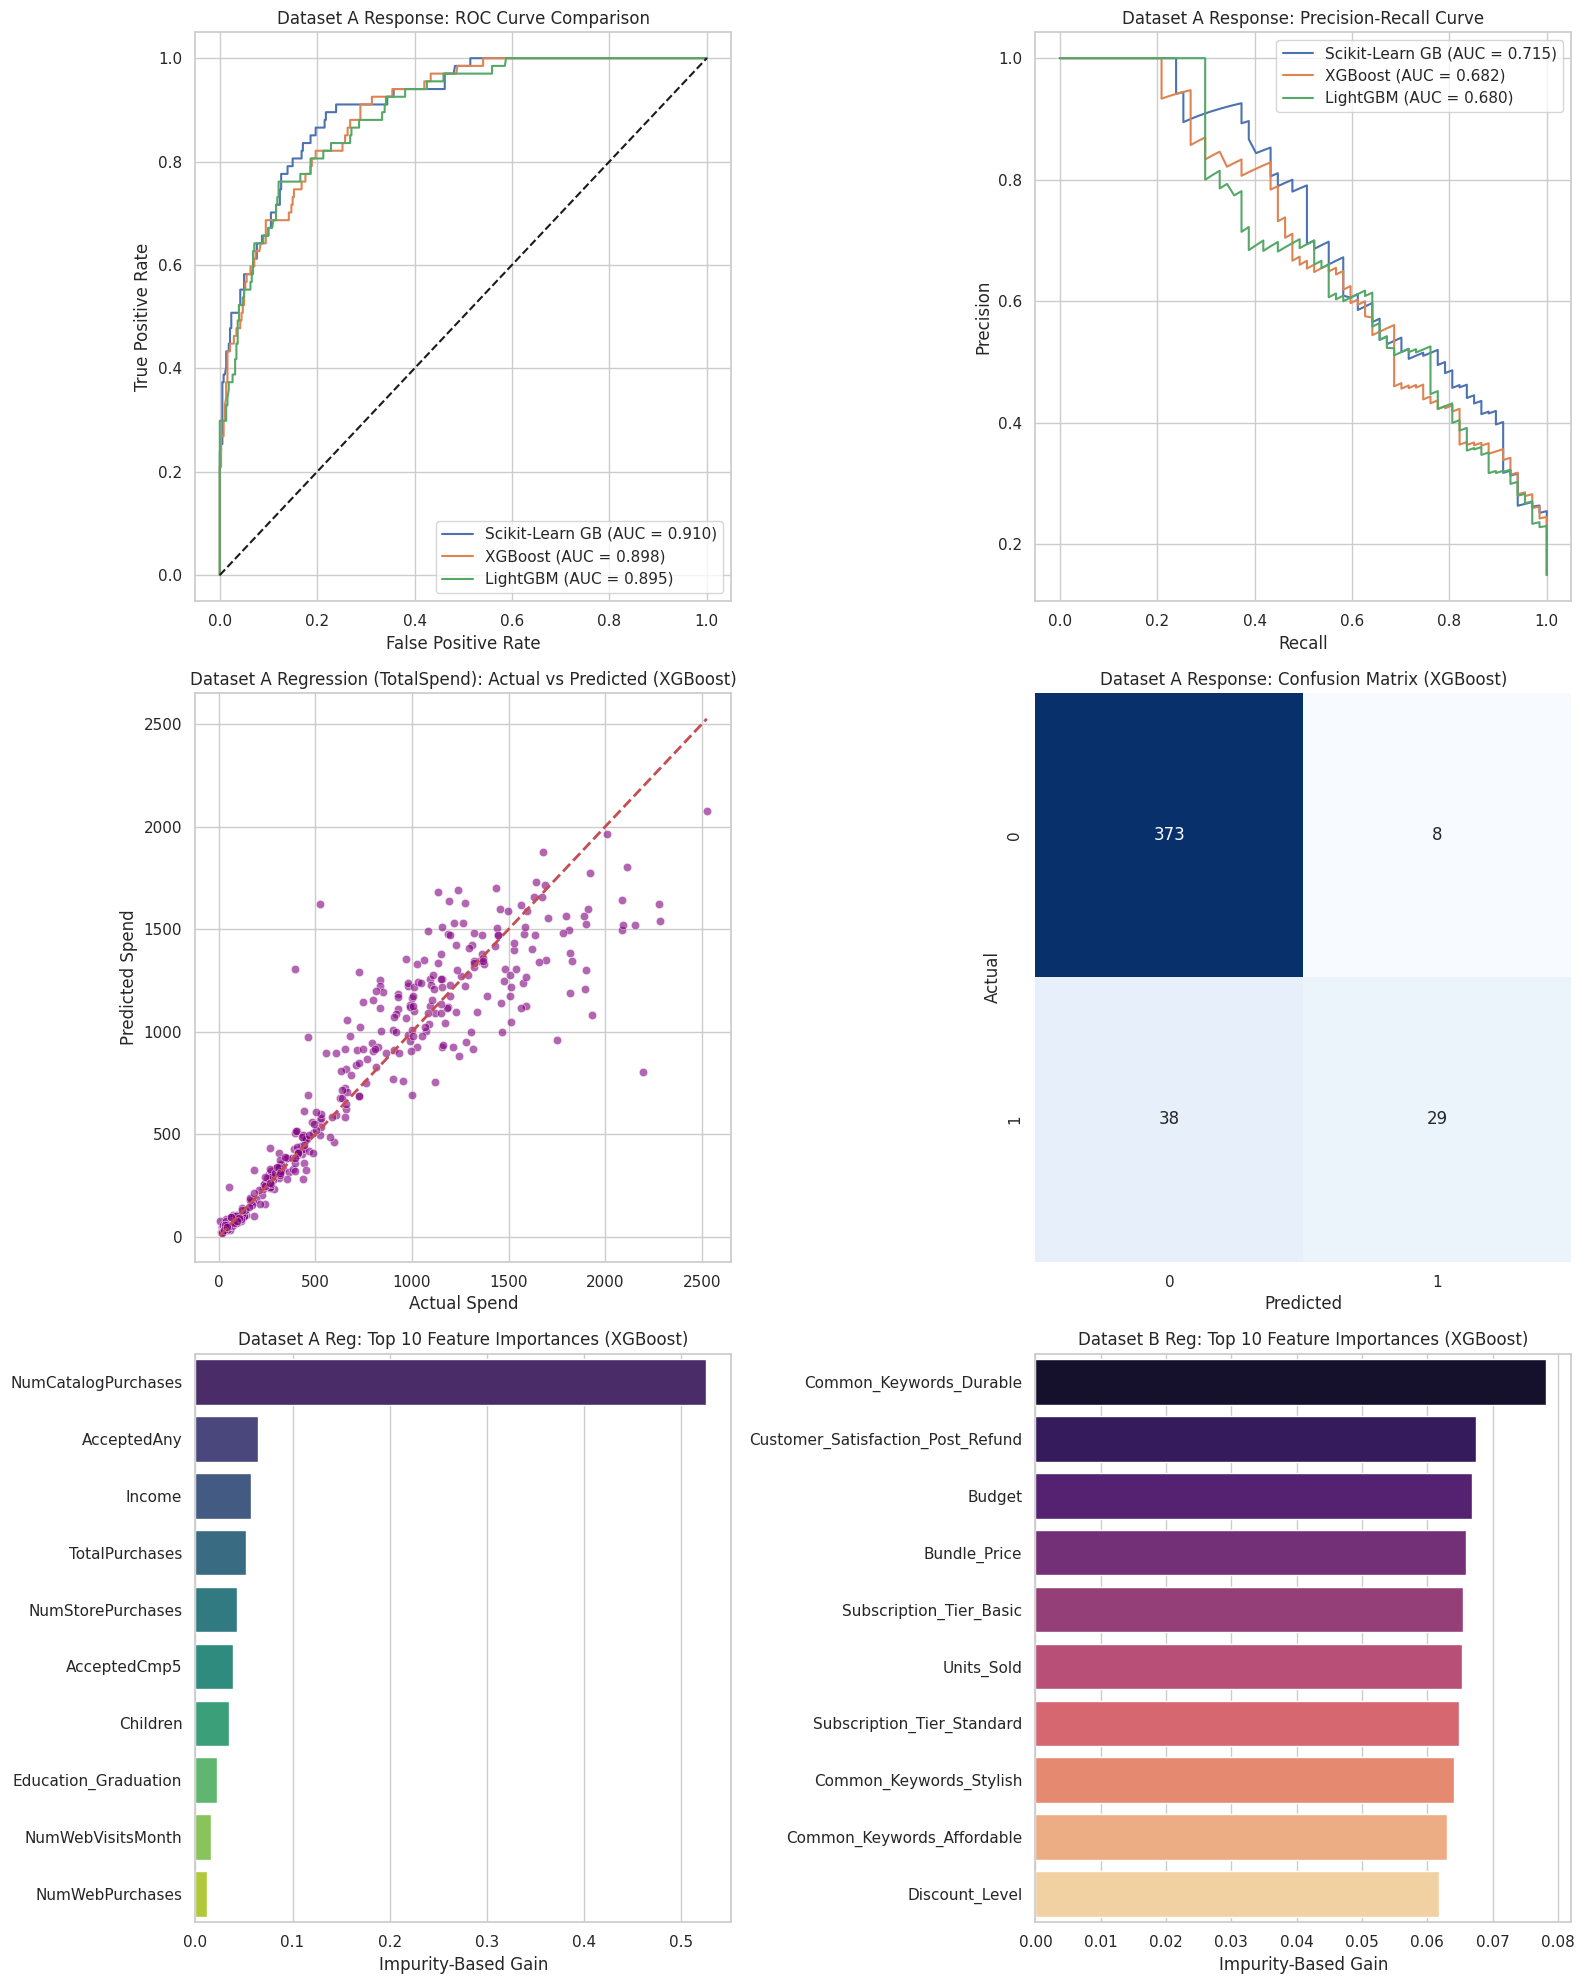

In [ ]:
# =========================================================================
# 8. DIAGNOSTIC VISUALIZATIONS & PLOTS
# =========================================================================
fig, axes = plt.subplots(3, 2, figsize=(16, 20))

# A. ROC Curves: Dataset A classification
for r in results_a_cls[:3]:  # Plot top 3 Boosting models
    fpr, tpr, _ = roc_curve(y_test_a, r['probs'])
    axes[0, 0].plot(fpr, tpr, label=f"{r['Model']} (AUC = {r['ROC-AUC']:.3f})")
axes[0, 0].plot([0, 1], [0, 1], 'k--')
axes[0, 0].set_title("Dataset A Response: ROC Curve Comparison")
axes[0, 0].set_xlabel("False Positive Rate")
axes[0, 0].set_ylabel("True Positive Rate")
axes[0, 0].legend()

# B. PR Curves: Dataset A classification
for r in results_a_cls[:3]:
    p, rec, _ = precision_recall_curve(y_test_a, r['probs'])
    axes[0, 1].plot(rec, p, label=f"{r['Model']} (AUC = {r['PR-AUC']:.3f})")
axes[0, 1].set_title("Dataset A Response: Precision-Recall Curve")
axes[0, 1].set_xlabel("Recall")
axes[0, 1].set_ylabel("Precision")
axes[0, 1].legend()

# C. Actual vs Predicted Spend (Dataset A Reg Champion)
best_reg_model = xgb_search_a_reg.best_estimator_ # XGBoost model typically champions regression
preds_a_reg_y = best_reg_model.predict(X_test_a_rp)
sns.scatterplot(x=y_test_a_r, y=preds_a_reg_y, ax=axes[1, 0], color='purple', alpha=0.6)
axes[1, 0].plot([y_test_a_r.min(), y_test_a_r.max()], [y_test_a_r.min(), y_test_a_r.max()], 'r--', lw=2)
axes[1, 0].set_title("Dataset A Regression (TotalSpend): Actual vs Predicted (XGBoost)")
axes[1, 0].set_xlabel("Actual Spend")
axes[1, 0].set_ylabel("Predicted Spend")

# D. Confusion Matrix (Dataset A Classification Champion)
best_cls_model = xgb_search_a.best_estimator_
cm_a = confusion_matrix(y_test_a, best_cls_model.predict(X_test_a_p))
sns.heatmap(cm_a, annot=True, fmt='d', cmap='Blues', ax=axes[1, 1], cbar=False)
axes[1, 1].set_title("Dataset A Response: Confusion Matrix (XGBoost)")
axes[1, 1].set_xlabel("Predicted")
axes[1, 1].set_ylabel("Actual")

# E. Feature Importances: Dataset A Regression (XGBoost)
importances_xgb_a = best_reg_model.feature_importances_
indices_xgb_a = np.argsort(importances_xgb_a)[::-1][:10]
sns.barplot(x=importances_xgb_a[indices_xgb_a], y=[feature_names_a[i] for i in indices_xgb_a], ax=axes[2, 0], palette='viridis')
axes[2, 0].set_title("Dataset A Reg: Top 10 Feature Importances (XGBoost)")
axes[2, 0].set_xlabel("Impurity-Based Gain")

# F. Feature Importances: Dataset B Regression (XGBoost)
best_reg_model_b = xgb_search_b_reg.best_estimator_
importances_xgb_b = best_reg_model_b.feature_importances_
indices_xgb_b = np.argsort(importances_xgb_b)[::-1][:10]
sns.barplot(x=importances_xgb_b[indices_xgb_b], y=[feature_names_b[i] for i in indices_xgb_b], ax=axes[2, 1], palette='magma')
axes[2, 1].set_title("Dataset B Reg: Top 10 Feature Importances (XGBoost)")
axes[2, 1].set_xlabel("Impurity-Based Gain")

plt.tight_layout()
plt.show()

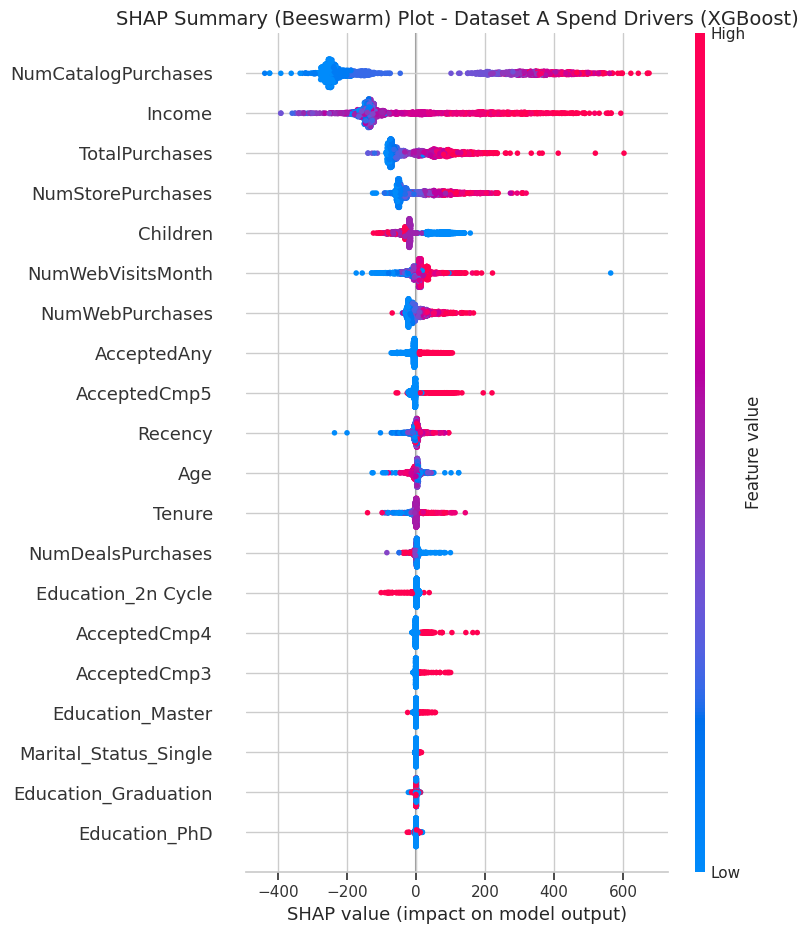

In [ ]:
# =========================================================================
# 9. SHAP VALUES EXPLANATION & SUMMARY PLOTS
# =========================================================================
try:
    # Using the optimized XGBoost Model for Dataset A continuous Spend
    explainer = shap.TreeExplainer(best_reg_model)
    shap_values = explainer(X_train_a_rp)

    # Generate SHAP Summary (Beeswarm) Plot
    plt.figure(figsize=(12, 6))
    shap.summary_plot(shap_values, features=X_train_a_rp, feature_names=feature_names_a, show=False)
    plt.title("SHAP Summary (Beeswarm) Plot - Dataset A Spend Drivers (XGBoost)", fontsize=14)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print("Could not generate SHAP values directly. Error message:", e)
    # Fallback to Partial Dependence Plots
    from sklearn.inspection import PartialDependenceDisplay
    fig, ax = plt.subplots(figsize=(12, 6))
    PartialDependenceDisplay.from_estimator(best_reg_model, X_train_a_rp, features=[0, 1, 2], feature_names=feature_names_a, ax=ax)
    plt.title("Fallback Partial Dependence Plots")
    plt.show()

# K-Means and silhouette score (Week 10)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')

# =========================================================================
# 1. LOAD AND AUDIT DATA
# =========================================================================
df_a = pd.read_csv('/content/Dataset A - Customer Analysis.csv', sep='\t')
df_b = pd.read_csv('/content/Dataset B - Marketing & Product Analysis.csv')

print("=== DATASET A AUDIT ===")
print("Shape:", df_a.shape)
print("Missing Values:\n", df_a.isnull().sum()[df_a.isnull().sum() > 0])

print("\n=== DATASET B AUDIT ===")
print("Shape:", df_b.shape)
print("Missing Values:\n", df_b.isnull().sum()[df_b.isnull().sum() > 0])

=== DATASET A AUDIT ===
Shape: (2240, 29)
Missing Values:
 Income    24
dtype: int64

=== DATASET B AUDIT ===
Shape: (10000, 17)
Missing Values:
 Series([], dtype: int64)


In [ ]:
# =========================================================================
# 2. FEATURE ENGINEERING & PREPROCESSING
# =========================================================================

# --- Dataset A: RFM Framework ---
df_a['Dt_Customer'] = pd.to_datetime(df_a['Dt_Customer'], errors='coerce')
income_median = df_a['Income'].median()
df_a['Income'] = df_a['Income'].fillna(income_median)

ref_date = pd.to_datetime('2015-01-01')
df_a['Age'] = 2015 - df_a['Year_Birth']
tenure_median = (ref_date - df_a['Dt_Customer']).dt.days.median()
df_a['Tenure'] = (ref_date - df_a['Dt_Customer']).dt.days.fillna(tenure_median)
df_a['Children'] = df_a['Kidhome'] + df_a['Teenhome']

purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_a['Frequency'] = df_a[purchase_cols].sum(axis=1)

spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df_a['Monetary'] = df_a[spend_cols].sum(axis=1)
df_a['Recency_RFM'] = df_a['Recency']  # Recency column (lower is more recent/better)

# Select RFM features for clustering
rfm_features = ['Recency_RFM', 'Frequency', 'Monetary']
X_a = df_a[rfm_features].copy()

# --- Dataset B: Performance Metrics ---
df_b['ConversionRate'] = np.where(df_b['Clicks'] > 0, df_b['Conversions'] / df_b['Clicks'], 0)
df_b['RevenuePerClick'] = np.where(df_b['Clicks'] > 0, df_b['Revenue_Generated'] / df_b['Clicks'], 0)
df_b['ProfitProxy'] = df_b['Revenue_Generated'] - df_b['Budget']

# Select numeric features for campaign clustering
camp_features = [
    'Budget', 'Clicks', 'Conversions', 'Revenue_Generated', 'ROI',
    'Discount_Level', 'Units_Sold', 'Bundle_Price', 'ConversionRate',
    'RevenuePerClick', 'ProfitProxy', 'Subscription_Length'
]
X_b = df_b[camp_features].copy()

# Scale Features (Mandatory for distance-based algorithms like K-Means)
scaler_a = StandardScaler()
X_a_scaled = scaler_a.fit_transform(X_a)

scaler_b = StandardScaler()
X_b_scaled = scaler_b.fit_transform(X_b)

print("Preprocessed Dataset A shape:", X_a_scaled.shape)
print("Preprocessed Dataset B shape:", X_b_scaled.shape)

Preprocessed Dataset A shape: (2240, 3)
Preprocessed Dataset B shape: (10000, 12)


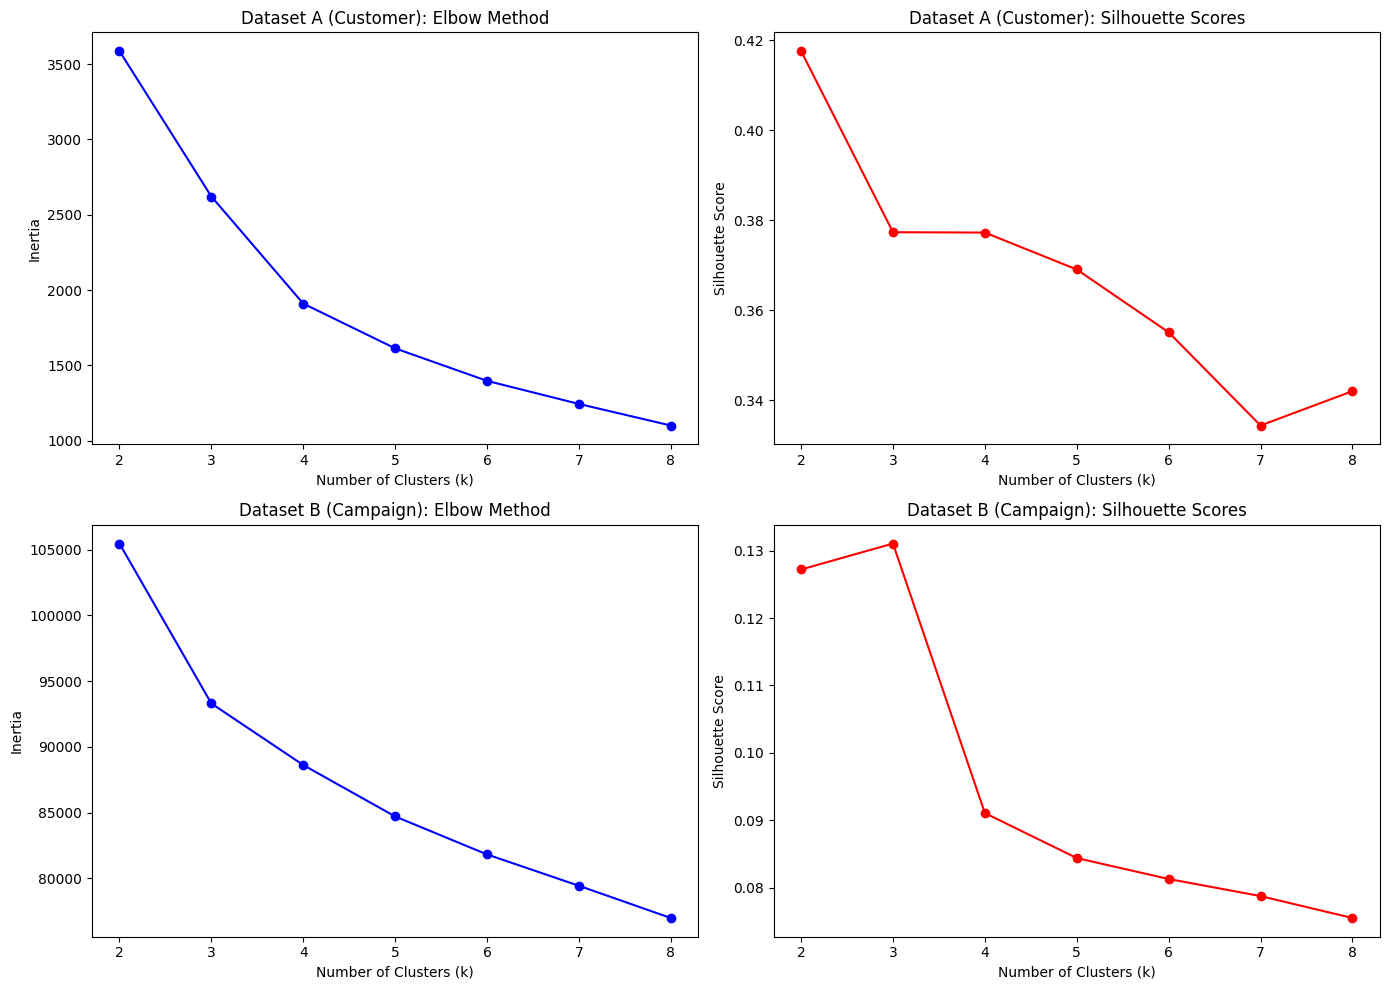

In [ ]:
# =========================================================================
# 3. CHOOSING K: ELBOW CURVE AND SILHOUETTE ANALYSIS
# =========================================================================

def analyze_k(X, max_k=8):
    inertias = []
    silhouettes = []
    k_range = range(2, max_k + 1)
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        labels = kmeans.fit_predict(X)
        inertias.append(kmeans.inertia_)
        silhouettes.append(silhouette_score(X, labels))
    return list(k_range), inertias, silhouettes

k_range_a, inertias_a, silhouettes_a = analyze_k(X_a_scaled)
k_range_b, inertias_b, silhouettes_b = analyze_k(X_b_scaled)

# Plot optimization curves
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Dataset A Curves
axes[0, 0].plot(k_range_a, inertias_a, 'bo-')
axes[0, 0].set_title("Dataset A (Customer): Elbow Method")
axes[0, 0].set_xlabel("Number of Clusters (k)")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(k_range_a, silhouettes_a, 'ro-')
axes[0, 1].set_title("Dataset A (Customer): Silhouette Scores")
axes[0, 1].set_xlabel("Number of Clusters (k)")
axes[0, 1].set_ylabel("Silhouette Score")

# Dataset B Curves
axes[1, 0].plot(k_range_b, inertias_b, 'bo-')
axes[1, 0].set_title("Dataset B (Campaign): Elbow Method")
axes[1, 0].set_xlabel("Number of Clusters (k)")
axes[1, 0].set_ylabel("Inertia")

axes[1, 1].plot(k_range_b, silhouettes_b, 'ro-')
axes[1, 1].set_title("Dataset B (Campaign): Silhouette Scores")
axes[1, 1].set_xlabel("Number of Clusters (k)")
axes[1, 1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

--- DATASET A K-MEANS RESULTS (k=3) ---
Overall Silhouette Score: 0.3773
Cluster
0    941
1    664
2    635
Name: count, dtype: int64


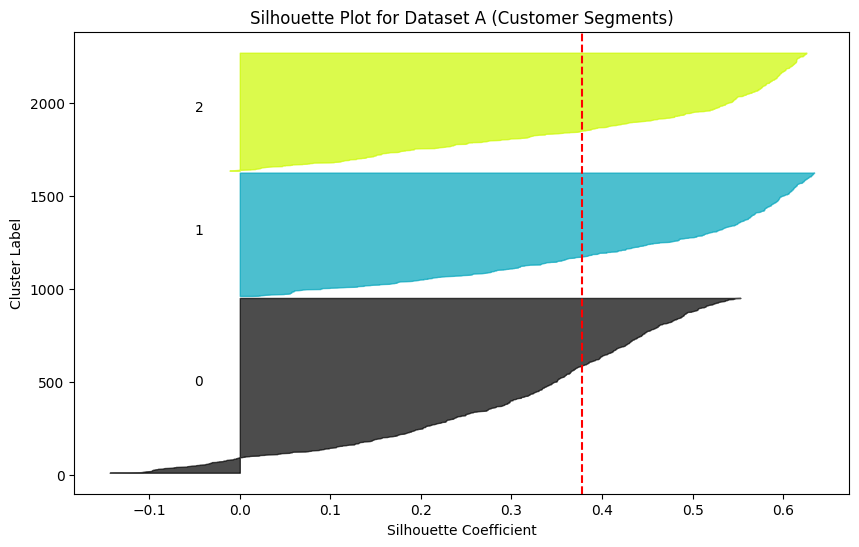

In [ ]:
# =========================================================================
# 4. K-MEANS FIT & SILHOUETTE PLOTS FOR DATASET A
# =========================================================================

# We choose k=3 for Customer RFM clustering
k_a = 3
kmeans_a = KMeans(n_clusters=k_a, random_state=42, n_init=10)
df_a['Cluster'] = kmeans_a.fit_predict(X_a_scaled)
sil_avg_a = silhouette_score(X_a_scaled, df_a['Cluster'])
sample_sil_values_a = silhouette_samples(X_a_scaled, df_a['Cluster'])

print(f"--- DATASET A K-MEANS RESULTS (k={k_a}) ---")
print(f"Overall Silhouette Score: {sil_avg_a:.4f}")
print(df_a['Cluster'].value_counts().sort_index())

# Silhouette Plot for Dataset A
plt.figure(figsize=(10, 6))
y_lower = 10
for i in range(k_a):
    ith_cluster_sil_values = sample_sil_values_a[df_a['Cluster'] == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = plt.cm.nipy_spectral(float(i) / k_a)
    plt.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_sil_values,
                      facecolor=color, edgecolor=color, alpha=0.7)
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

plt.title("Silhouette Plot for Dataset A (Customer Segments)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster Label")
plt.axvline(x=sil_avg_a, color="red", linestyle="--")
plt.show()

--- DATASET B K-MEANS RESULTS (k=3) ---
Overall Silhouette Score: 0.1310
Cluster
0    4985
1    4954
2      61
Name: count, dtype: int64


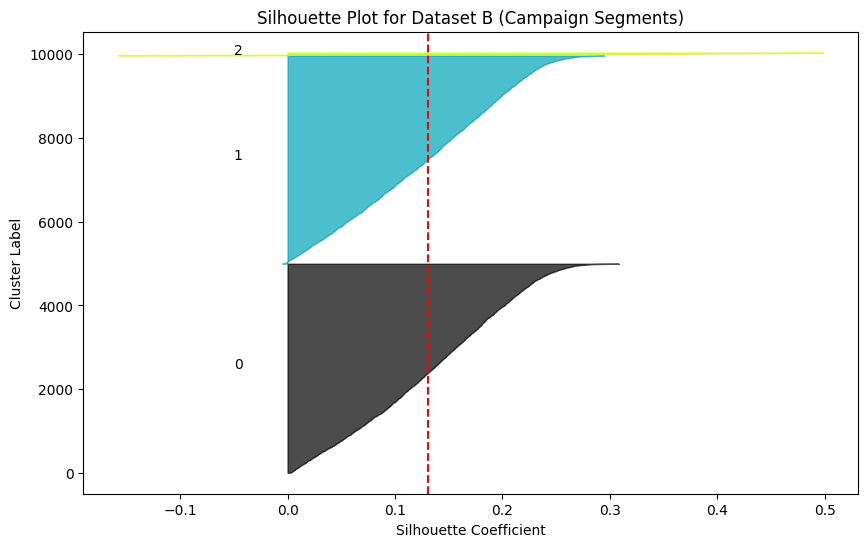

In [ ]:
# =========================================================================
# 5. K-MEANS FIT & SILHOUETTE PLOTS FOR DATASET B
# =========================================================================

# We choose k=3 for Campaign performance clustering
k_b = 3
kmeans_b = KMeans(n_clusters=k_b, random_state=42, n_init=10)
df_b['Cluster'] = kmeans_b.fit_predict(X_b_scaled)
sil_avg_b = silhouette_score(X_b_scaled, df_b['Cluster'])
sample_sil_values_b = silhouette_samples(X_b_scaled, df_b['Cluster'])

print(f"--- DATASET B K-MEANS RESULTS (k={k_b}) ---")
print(f"Overall Silhouette Score: {sil_avg_b:.4f}")
print(df_b['Cluster'].value_counts().sort_index())

# Silhouette Plot for Dataset B
plt.figure(figsize=(10, 6))
y_lower = 10
for i in range(k_b):
    ith_cluster_sil_values = sample_sil_values_b[df_b['Cluster'] == i]
    ith_cluster_sil_values.sort()
    size_cluster_i = ith_cluster_sil_values.shape[0]
    y_upper = y_lower + size_cluster_i

    color = plt.cm.nipy_spectral(float(i) / k_b)
    plt.fill_betweenx(np.arange(y_lower, y_upper),
                      0, ith_cluster_sil_values,
                      facecolor=color, edgecolor=color, alpha=0.7)
    plt.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
    y_lower = y_upper + 10

plt.title("Silhouette Plot for Dataset B (Campaign Segments)")
plt.xlabel("Silhouette Coefficient")
plt.ylabel("Cluster Label")
plt.axvline(x=sil_avg_b, color="red", linestyle="--")
plt.show()

In [ ]:
# =========================================================================
# 6. PROFILE CUSTOMER CLUSTERS (DATASET A)
# =========================================================================

# Re-engineer AcceptedAny on df_a if it was dropped or not defined
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
if 'AcceptedAny' not in df_a.columns:
    df_a['AcceptedAny'] = (df_a[cmp_cols].sum(axis=1) > 0).astype(int)

# Map original non-scaled features to interpret means
profile_a = df_a.groupby('Cluster')[['Recency_RFM', 'Frequency', 'Monetary', 'Income', 'Age', 'AcceptedAny']].mean()
display(profile_a)

# =========================================================================
# 7. PROFILE CAMPAIGN CLUSTERS (DATASET B)
# =========================================================================
profile_b = df_b.groupby('Cluster')[['Budget', 'Revenue_Generated', 'ROI', 'ProfitProxy', 'ConversionRate']].mean()
display(profile_b)

,Recency_RFM,Frequency,Monetary,Income,Age,AcceptedAny
Cluster,,,,,,
0,49.065887,22.156217,1201.744952,69825.394261,48.121148,0.353879
1,23.768072,9.418675,164.121988,39594.667922,44.402108,0.102410
2,75.672441,9.744882,184.518110,39396.077953,45.212598,0.097638


,Budget,Revenue_Generated,ROI,ProfitProxy,ConversionRate
Cluster,,,,,
0,28576.045938,26447.808321,2.765065,-2128.237617,0.492422
1,21894.608203,73623.419253,2.749978,51728.811050,0.438027
2,28173.724590,62516.923443,2.564098,34343.198852,24.145352


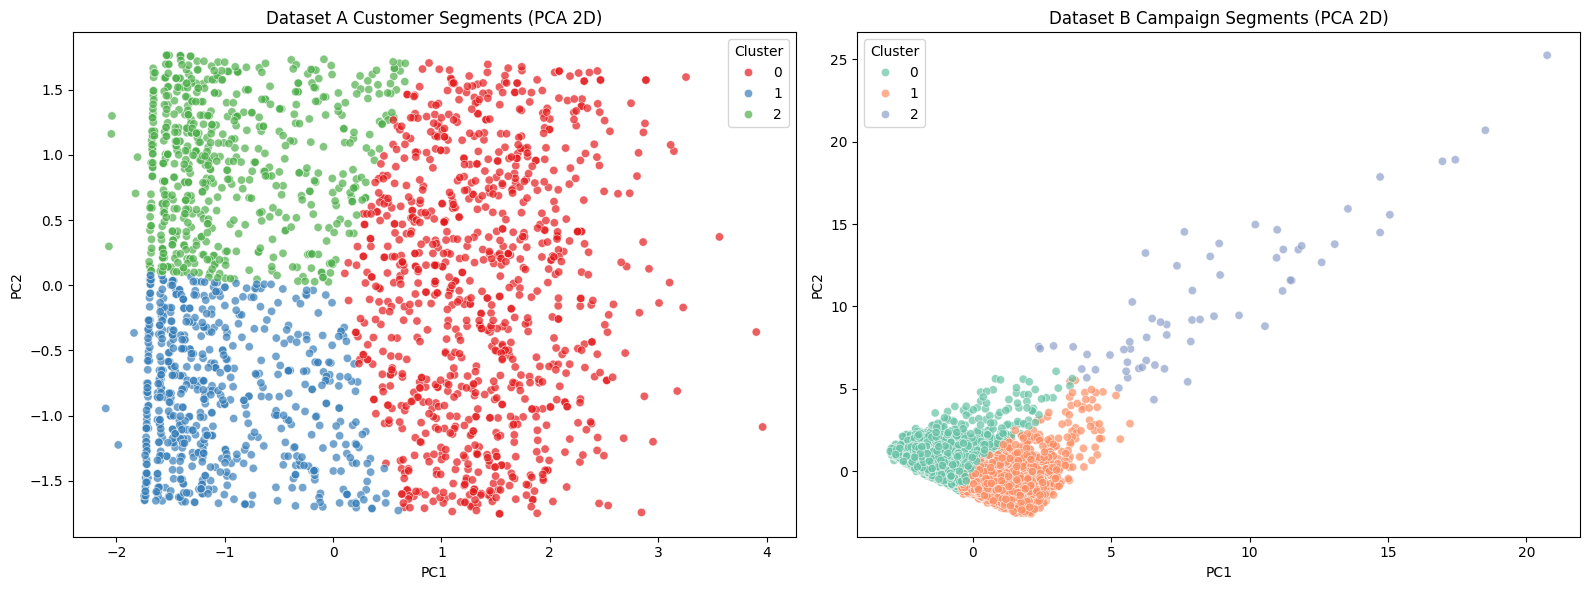

In [ ]:
# =========================================================================
# 8. PCA 2D PROJECTION OF CLUSTERS
# =========================================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA Dataset A
pca_a = PCA(n_components=2)
coords_a = pca_a.fit_transform(X_a_scaled)
sns.scatterplot(x=coords_a[:, 0], y=coords_a[:, 1], hue=df_a['Cluster'], palette='Set1', alpha=0.7, ax=axes[0])
axes[0].set_title("Dataset A Customer Segments (PCA 2D)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# PCA Dataset B
pca_b = PCA(n_components=2)
coords_b = pca_b.fit_transform(X_b_scaled)
sns.scatterplot(x=coords_b[:, 0], y=coords_b[:, 1], hue=df_b['Cluster'], palette='Set2', alpha=0.7, ax=axes[1])
axes[1].set_title("Dataset B Campaign Segments (PCA 2D)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [ ]:
# =========================================================================
# 9. STABILITY CHECK USING ADJUSTED RAND INDEX (ARI)
# =========================================================================
kmeans_stable = KMeans(n_clusters=3, random_state=123, n_init=10)
stable_labels_a = kmeans_stable.fit_predict(X_a_scaled)

ari_score = adjusted_rand_score(df_a['Cluster'], stable_labels_a)
print(f"Adjusted Rand Index between runs (Seed 42 vs 123) for Dataset A: {ari_score:.4f}")

Adjusted Rand Index between runs (Seed 42 vs 123) for Dataset A: 1.0000


# DBSCAN and Hierarchical Agglomerative Clustering (Week 11)

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score
from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist
import warnings
warnings.filterwarnings('ignore')

# Set random seed for reproducibility
np.random.seed(42)

# ==========================================
# 1. LOAD DATASETS
# ==========================================
path_a = '/content/Dataset A - Customer Analysis.csv'
path_b = '/content/Dataset B - Marketing & Product Analysis.csv'

df_a_raw = pd.read_csv(path_a, sep='\t')
df_b_raw = pd.read_csv(path_b)

# ==========================================
# 2. FEATURE ENGINEERING
# ==========================================
# --- Dataset A Feature Engineering ---
df_a = df_a_raw.copy()
df_a['Dt_Customer'] = pd.to_datetime(df_a['Dt_Customer'], errors='coerce')
income_median = df_a['Income'].median()
df_a['Income'] = df_a['Income'].fillna(income_median)

ref_date = pd.to_datetime('2015-01-01')
df_a['Age'] = 2015 - df_a['Year_Birth']
tenure_median = (ref_date - df_a['Dt_Customer']).dt.days.median()
df_a['Tenure'] = (ref_date - df_a['Dt_Customer']).dt.days.fillna(tenure_median)
df_a['Children'] = df_a['Kidhome'] + df_a['Teenhome']

purchase_cols = ['NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
df_a['Frequency'] = df_a[purchase_cols].sum(axis=1)

spend_cols = ['MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds']
df_a['Monetary'] = df_a[spend_cols].sum(axis=1)
df_a['Recency_RFM'] = df_a['Recency']

# Primary segmentation features (RFM)
rfm_features = ['Recency_RFM', 'Frequency', 'Monetary']
X_a = df_a[rfm_features].copy()

# --- Dataset B Feature Engineering ---
df_b = df_b_raw.copy()
df_b['ConversionRate'] = np.where(df_b['Clicks'] > 0, df_b['Conversions'] / df_b['Clicks'], 0)
df_b['RevenuePerClick'] = np.where(df_b['Clicks'] > 0, df_b['Revenue_Generated'] / df_b['Clicks'], 0)
df_b['ProfitProxy'] = df_b['Revenue_Generated'] - df_b['Budget']

camp_features = [
    'Budget', 'Clicks', 'Conversions', 'Revenue_Generated', 'ROI',
    'Discount_Level', 'Units_Sold', 'Bundle_Price', 'ConversionRate',
    'RevenuePerClick', 'ProfitProxy', 'Subscription_Length'
]
X_b = df_b[camp_features].copy()

# Scale Features (Mandatory for distance-based clustering algorithms)
scaler_a = StandardScaler()
X_a_scaled = scaler_a.fit_transform(X_a)

scaler_b = StandardScaler()
X_b_scaled = scaler_b.fit_transform(X_b)

print("Dataset A preprocessed features shape:", X_a_scaled.shape)
print("Dataset B preprocessed features shape:", X_b_scaled.shape)

Dataset A preprocessed features shape: (2240, 3)
Dataset B preprocessed features shape: (10000, 12)


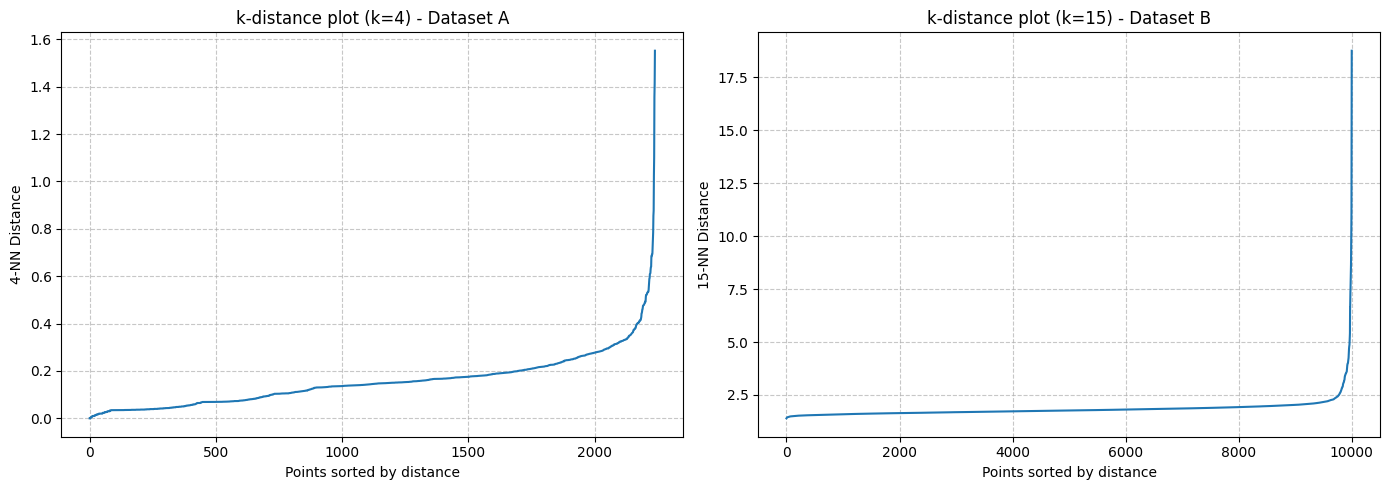

In [ ]:
# ==========================================
# 3. DBSCAN EPSILON SELECTION (K-DISTANCE PLOTS)
# ==========================================
from sklearn.neighbors import NearestNeighbors

def plot_k_distance(X, k, ax, title):
    neigh = NearestNeighbors(n_neighbors=k)
    nbrs = neigh.fit(X)
    distances, indices = nbrs.kneighbors(X)
    distances = np.sort(distances[:, k-1], axis=0)
    ax.plot(distances)
    ax.set_title(f"k-distance plot (k={k}) - {title}")
    ax.set_xlabel("Points sorted by distance")
    ax.set_ylabel(f"{k}-NN Distance")
    ax.grid(True, linestyle='--', alpha=0.7)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_k_distance(X_a_scaled, k=4, ax=axes[0], title="Dataset A")
plot_k_distance(X_b_scaled, k=15, ax=axes[1], title="Dataset B")
plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 4. DBSCAN IMPLEMENTATION & EVALUATION
# ==========================================

# Dataset A DBSCAN Tuning (Selected from k-distance elbow curve range ~0.4 to 0.7)
eps_a = 0.5
min_samples_a = 4
db_a = DBSCAN(eps=eps_a, min_samples=min_samples_a)
labels_db_a = db_a.fit_predict(X_a_scaled)

non_noise_mask_a = labels_db_a != -1
n_clusters_db_a = len(set(labels_db_a)) - (1 if -1 in labels_db_a else 0)
n_noise_a = np.sum(labels_db_a == -1)
sil_db_a = silhouette_score(X_a_scaled[non_noise_mask_a], labels_db_a[non_noise_mask_a]) if n_clusters_db_a > 1 else -1

# Dataset B DBSCAN Tuning (Selected from k-distance elbow curve range ~1.2 to 2.5)
eps_b = 2.0
min_samples_b = 15
db_b = DBSCAN(eps=eps_b, min_samples=min_samples_b)
labels_db_b = db_b.fit_predict(X_b_scaled)

non_noise_mask_b = labels_db_b != -1
n_clusters_db_b = len(set(labels_db_b)) - (1 if -1 in labels_db_b else 0)
n_noise_b = np.sum(labels_db_b == -1)
sil_db_b = silhouette_score(X_b_scaled[non_noise_mask_b], labels_db_b[non_noise_mask_b]) if n_clusters_db_b > 1 else -1

print("--- DBSCAN Results: Dataset A ---")
print(f"Number of Clusters: {n_clusters_db_a}")
print(f"Noise Points: {n_noise_a} / {len(df_a)} ({n_noise_a/len(df_a)*100:.2f}%)")
print(f"Silhouette Score (on non-noise): {sil_db_a:.4f}")

print("\n--- DBSCAN Results: Dataset B ---")
print(f"Number of Clusters: {n_clusters_db_b}")
print(f"Noise Points: {n_noise_b} / {len(df_b)} ({n_noise_b/len(df_b)*100:.2f}%)")
print(f"Silhouette Score (on non-noise): {sil_db_b:.4f}")

--- DBSCAN Results: Dataset A ---
Number of Clusters: 1
Noise Points: 18 / 2240 (0.80%)
Silhouette Score (on non-noise): -1.0000

--- DBSCAN Results: Dataset B ---
Number of Clusters: 1
Noise Points: 253 / 10000 (2.53%)
Silhouette Score (on non-noise): -1.0000


In [ ]:
# ==========================================
# 5. HAC IMPLEMENTATION: LINKAGE & COPHENETIC ANALYSIS
# ==========================================

def evaluate_hac(X, title):
    linkages = ['ward', 'complete', 'average', 'single']
    cophenetic_scores = {}
    Y = pdist(X)

    for l_type in linkages:
        # Ward's link is constrained to Euclidean metric
        Z = linkage(X, method=l_type, metric='euclidean')
        c_coeff, coph_dists = cophenet(Z, Y)
        cophenetic_scores[l_type] = c_coeff
        print(f"{title} - Linkage: {l_type:10s} Cophenetic Coefficient: {c_coeff:.4f}")
    return cophenetic_scores

print("--- HAC Analysis for Dataset A ---")
coph_scores_a = evaluate_hac(X_a_scaled, "Dataset A")

print("\n--- HAC Analysis for Dataset B ---")
coph_scores_b = evaluate_hac(X_b_scaled, "Dataset B")

--- HAC Analysis for Dataset A ---
Dataset A - Linkage: ward       Cophenetic Coefficient: 0.6590
Dataset A - Linkage: complete   Cophenetic Coefficient: 0.6777
Dataset A - Linkage: average    Cophenetic Coefficient: 0.6983
Dataset A - Linkage: single     Cophenetic Coefficient: 0.4155

--- HAC Analysis for Dataset B ---
Dataset B - Linkage: ward       Cophenetic Coefficient: 0.2439
Dataset B - Linkage: complete   Cophenetic Coefficient: 0.7951
Dataset B - Linkage: average    Cophenetic Coefficient: 0.8156
Dataset B - Linkage: single     Cophenetic Coefficient: 0.8034


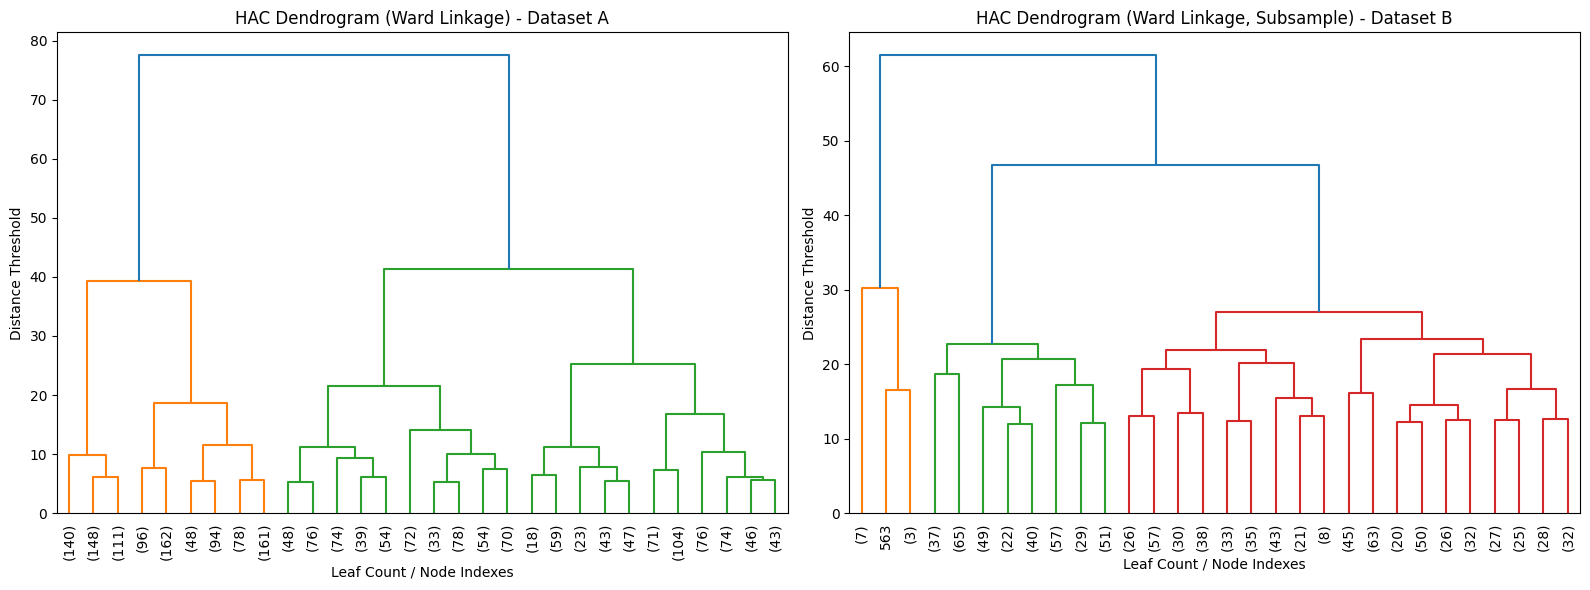

In [ ]:
# ==========================================
# 6. DENDROGRAM GENERATION & OPTIMAL CUTTING
# ==========================================

# Dataset A linkage
Z_a = linkage(X_a_scaled, method='ward', metric='euclidean')

# Dataset B linkage (Using a subsample of 1000 records for clear dendrogram processing speed)
Z_b_sub = linkage(X_b_scaled[:1000], method='ward', metric='euclidean')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

dendrogram(Z_a, truncate_mode='lastp', p=30, ax=axes[0], show_leaf_counts=True, leaf_rotation=90)
axes[0].set_title("HAC Dendrogram (Ward Linkage) - Dataset A")
axes[0].set_xlabel("Leaf Count / Node Indexes")
axes[0].set_ylabel("Distance Threshold")

dendrogram(Z_b_sub, truncate_mode='lastp', p=30, ax=axes[1], show_leaf_counts=True, leaf_rotation=90)
axes[1].set_title("HAC Dendrogram (Ward Linkage, Subsample) - Dataset B")
axes[1].set_xlabel("Leaf Count / Node Indexes")
axes[1].set_ylabel("Distance Threshold")

plt.tight_layout()
plt.show()

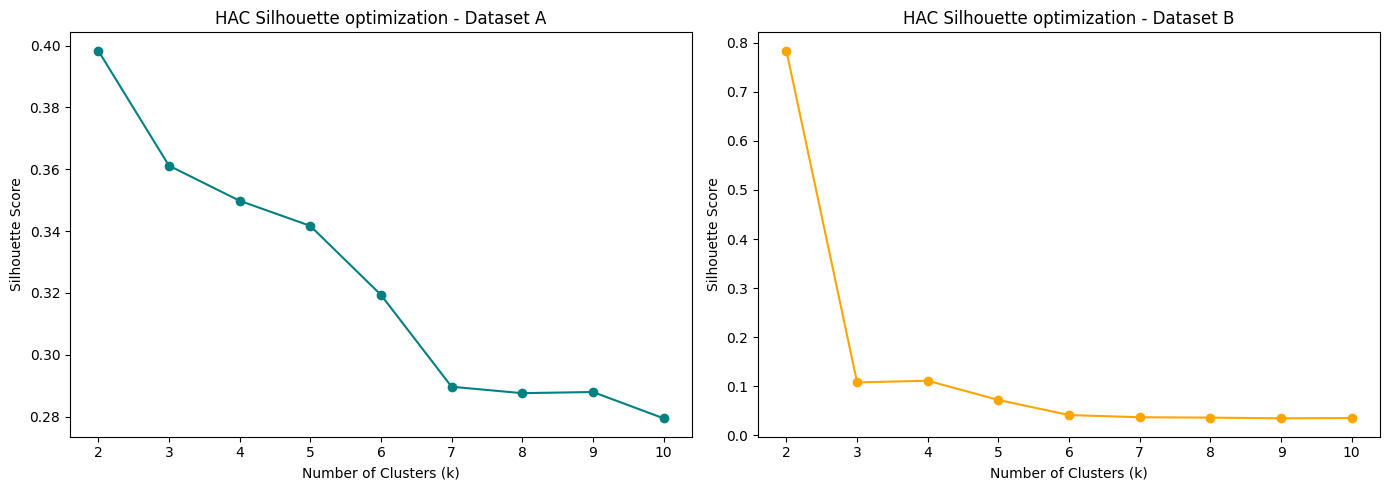

In [ ]:
# ==========================================
# 7. CHOOSE K FOR HAC VIA SILHOUETTE SCORE
# ==========================================

def optimize_hac_k(X, k_range):
    scores = []
    for k in k_range:
        hac = AgglomerativeClustering(n_clusters=k, metric='euclidean', linkage='ward')
        labels = hac.fit_predict(X)
        scores.append(silhouette_score(X, labels))
    return scores

ks = list(range(2, 11))
sil_scores_hac_a = optimize_hac_k(X_a_scaled, ks)
sil_scores_hac_b = optimize_hac_k(X_b_scaled[:3000], ks) # Subsample for speed

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(ks, sil_scores_hac_a, 'bo-', color='teal')
axes[0].set_title("HAC Silhouette optimization - Dataset A")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Silhouette Score")

axes[1].plot(ks, sil_scores_hac_b, 'ro-', color='orange')
axes[1].set_title("HAC Silhouette optimization - Dataset B")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

In [ ]:
# ==========================================
# 8. COMPARE DBSCAN VS HAC VS WEEK 10 K-MEANS
# ==========================================

# Run Ward HAC with optimal k=3
hac_a = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels_hac_a = hac_a.fit_predict(X_a_scaled)

hac_b = AgglomerativeClustering(n_clusters=3, metric='euclidean', linkage='ward')
labels_hac_b = hac_b.fit_predict(X_b_scaled)

# Re-extract Week 10 K-Means labels
kmeans_a = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_a_scaled)
labels_km_a = kmeans_a.labels_

kmeans_b = KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_b_scaled)
labels_km_b = kmeans_b.labels_

# Evaluate Alignments using Adjusted Rand Index (ARI) and Normalized Mutual Information (NMI)
print("=== CLUSTERING ALIGNMENT AUDITS ===")
print("Dataset A (Customer Profiling):")
print(f"  HAC vs K-Means ARI: {adjusted_rand_score(labels_hac_a, labels_km_a):.4f}")
print(f"  HAC vs K-Means NMI: {normalized_mutual_info_score(labels_hac_a, labels_km_a):.4f}")

print("\nDataset B (Campaign Performance):")
print(f"  HAC vs K-Means ARI: {adjusted_rand_score(labels_hac_b, labels_km_b):.4f}")
print(f"  HAC vs K-Means NMI: {normalized_mutual_info_score(labels_hac_b, labels_km_b):.4f}")

=== CLUSTERING ALIGNMENT AUDITS ===
Dataset A (Customer Profiling):
  HAC vs K-Means ARI: 0.3457
  HAC vs K-Means NMI: 0.4376

Dataset B (Campaign Performance):
  HAC vs K-Means ARI: 0.5154
  HAC vs K-Means NMI: 0.4317


In [ ]:
# ==========================================
# 9. CLUSTER & NOISE PROFILING AND CENTROID ANALYSIS
# ==========================================

# Safely compute missing 'AcceptedAny' on df_a if it does not exist
cmp_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5']
if 'AcceptedAny' not in df_a.columns:
    df_a['AcceptedAny'] = (df_a[cmp_cols].sum(axis=1) > 0).astype(int)

# Attach DBSCAN and HAC labels to Dataset A
df_a['DBSCAN_Cluster'] = labels_db_a
df_a['HAC_Cluster'] = labels_hac_a
df_a['KMeans_Cluster'] = labels_km_a

# Profile Customer segments (including Noise group '-1')
print("=== DATASET A SEGMENT PROFILES (DBSCAN) ===")
profile_db_a = df_a.groupby('DBSCAN_Cluster')[['Recency_RFM', 'Frequency', 'Monetary', 'Income', 'Age', 'AcceptedAny', 'Response']].mean()
display(profile_db_a)

# Attach DBSCAN and HAC labels to Dataset B
df_b['DBSCAN_Cluster'] = labels_db_b
df_b['HAC_Cluster'] = labels_hac_b
df_b['KMeans_Cluster'] = labels_km_b

print("\n=== DATASET B SEGMENT PROFILES (DBSCAN) ===")
profile_db_b = df_b.groupby('DBSCAN_Cluster')[['Budget', 'Revenue_Generated', 'ROI', 'ProfitProxy', 'ConversionRate', 'Subscription_Length']].mean()
display(profile_db_b)

=== DATASET A SEGMENT PROFILES (DBSCAN) ===


,Recency_RFM,Frequency,Monetary,Income,Age,AcceptedAny,Response
DBSCAN_Cluster,,,,,,,
-1,48.388889,27.000000,1775.833333,76809.750000,42.388889,0.555556,0.500000
0,49.115212,14.763726,596.319982,52038.924167,46.225023,0.203870,0.146265



=== DATASET B SEGMENT PROFILES (DBSCAN) ===


,Budget,Revenue_Generated,ROI,ProfitProxy,ConversionRate,Subscription_Length
DBSCAN_Cluster,,,,,,
-1,26869.985613,57407.557431,2.623992,30537.571818,10.323217,17.833992
0,25221.911242,49847.354443,2.759801,24625.443201,0.357629,18.021237


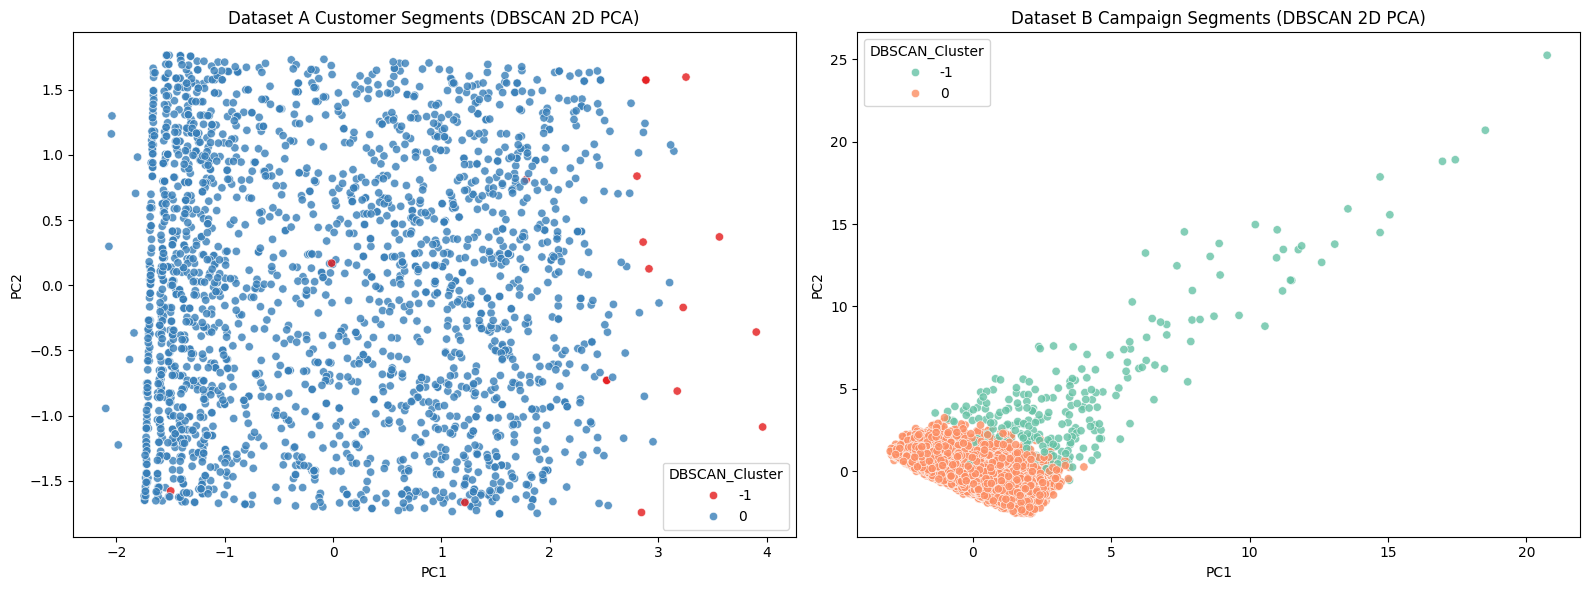

In [ ]:
# ==========================================
# 10. DIAGNOSTIC SCATTER PROJECTIONS (PCA 2D)
# ==========================================

# Ensure cluster columns are attached to prevent KeyErrors
df_a['DBSCAN_Cluster'] = labels_db_a
df_b['DBSCAN_Cluster'] = labels_db_b

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# PCA Dataset A DBSCAN
pca_a = PCA(n_components=2)ƒ
coords_a = pca_a.fit_transform(X_a_scaled)
sns.scatterplot(x=coords_a[:, 0], y=coords_a[:, 1], hue=df_a['DBSCAN_Cluster'], palette='Set1', alpha=0.8, ax=axes[0])
axes[0].set_title("Dataset A Customer Segments (DBSCAN 2D PCA)")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# PCA Dataset B DBSCAN
pca_b = PCA(n_components=2)
coords_b = pca_b.fit_transform(X_b_scaled)
sns.scatterplot(x=coords_b[:, 0], y=coords_b[:, 1], hue=df_b['DBSCAN_Cluster'], palette='Set2', alpha=0.8, ax=axes[1])
axes[1].set_title("Dataset B Campaign Segments (DBSCAN 2D PCA)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

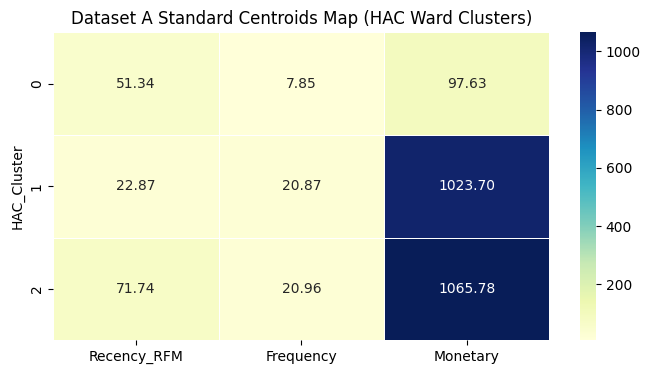

In [ ]:
# ==========================================
# 11. CENTROID HEATMAP COMPARISONS
# ==========================================

# Calculate Centroids for standard features of Dataset A across HAC clusters
centroids_hac_a = df_a.groupby('HAC_Cluster')[rfm_features].mean()

plt.figure(figsize=(8, 4))
sns.heatmap(centroids_hac_a, annot=True, fmt=".2f", cmap='YlGnBu', linewidths=0.5)
plt.title("Dataset A Standard Centroids Map (HAC Ward Clusters)")
plt.show()

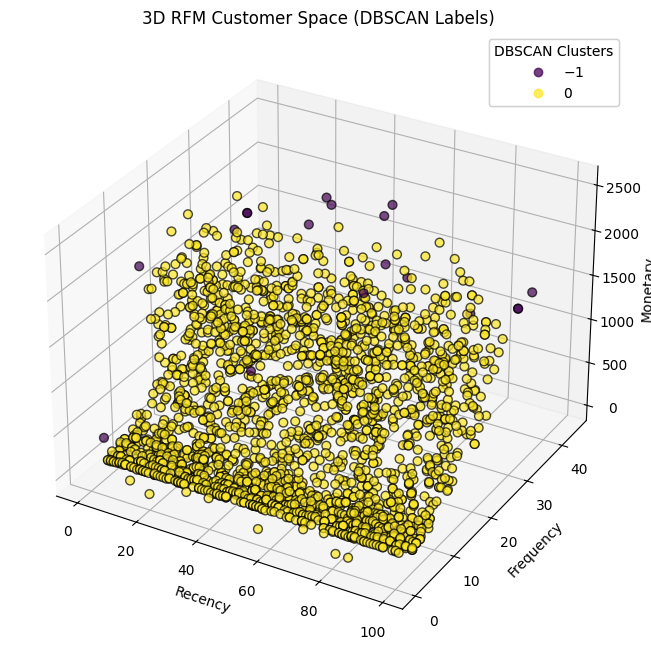

In [ ]:
# ==========================================
# 12. 3D SCATTER PROJECT OF CUSTOMER RFM SEGMENTS
# ==========================================
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# Color mapping for DBSCAN clusters (including Noise = -1)
scatter = ax.scatter(
    df_a['Recency_RFM'],
    df_a['Frequency'],
    df_a['Monetary'],
    c=df_a['DBSCAN_Cluster'],
    cmap='viridis',
    edgecolor='k',
    s=40,
    alpha=0.7
)

ax.set_title("3D RFM Customer Space (DBSCAN Labels)")
ax.set_xlabel("Recency")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")

# Produce a legend
legend1 = ax.legend(*scatter.legend_elements(), title="DBSCAN Clusters")
ax.add_artist(legend1)

plt.show()